In [1]:
from mltau.tools.evaluation import evaluate_daughter_model as ed
from mltau.tools.evaluation import decode_HPS as dh

In [2]:
import awkward as ak
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

In [3]:
from hydra import compose, initialize

with initialize(version_base=None, config_path="../config", job_name="test_app"):
    cfg = compose(config_name="main_ParTauDETR")

In [4]:
ParTauDETR_runs = {
  # "baseline" : "20261022_ParTauDETR_120epochs_logIP_boundAngles_v2",
  # "lr0p0001" : "20261021_ParTauDETR_150epochs_logIP_boundAngles_lr0p0001",
  # "fixedMass" : "20261022_ParTauDETR_120epochs_logIP_boundAngles_fixedMass_v3",
    "original": "20261003_ParTauDETR_120epochs_logSignificanceIPs",
    "baseline": "20261007_ParTauDETR_120epochs_baseline",
    "fixedToPionMass": "20261007_ParTauDETR_120epochs_massFromMeson",
    "logIP": "20261020_ParTauDETR_120epochs_logIP",
    "noMassless": "20261021_ParTauDETR_120epochs_logIP_noMassless",
    "best": "20261007_ParTauDETR_120epochs_best",
    "fixedMassV3": "20261022_ParTauDETR_120epochs_logIP_boundAngles_fixedMass_v3",
}
HPS_pred_path = "/local/laurits/20260726_HPS_results_tauDaughter/z_test.parquet"
skip_pred_vs_true_2d = True

In [5]:
output_dir = os.path.expanduser("~/HPS_kin_eval/unboundAngles_oldData")
os.makedirs(output_dir, exist_ok=True)

In [6]:
hps_data = ak.from_parquet(HPS_pred_path)
sts_runs = {
    name: ak.from_parquet(f"/home/karl/tmp/{run}-model_best-0p500thr/z_test_predictions.parquet")
    for name, run in ParTauDETR_runs.items()
}

In [7]:
charged_pdg = [321, 211]
neutral_pdg = [221, 111, 130]

In [8]:
def count_ch_neutral(pdg):
    charged = ak.sum(
        (abs(pdg) == 321) | (abs(pdg) == 211),
        axis=1
    )
    
    neutral = ak.sum(
        (abs(pdg) == 221) |
        (abs(pdg) == 111) |
        (abs(pdg) == 130),
        axis=1
    )
    return charged, neutral

In [9]:
from mltau.tools import general as g

In [10]:
pred_hps_x, true_hps_x = ed.hps_x_dm0(hps_data)
predictions = {"HPS": pred_hps_x}
for name, data in sts_runs.items():
    dm0_mask = data.tau_decaymode == 0
    pred_energy = g.reinitialize_p4(data.tau_p4).energy[dm0_mask]
    predictions[name] = ed.calculate_x_dm0(E_pi=pred_energy)

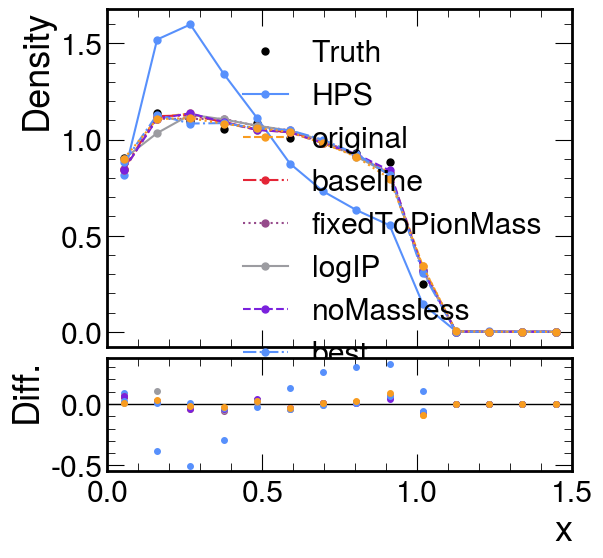

In [11]:
ed.plot_performance(predictions, true_hps_x)


In [12]:
explicit_decay_modes = [0, 1, 2, 10, 11, 12]
categories = [*explicit_decay_modes, 15] # 15 stands for all "rare" decay modes

def reduce_decay_modes(decay_modes, invalid_decay_mode):
    # Remaps valid decay modes not in the explicit list to 15,
    # all other decay modes are invalid and are thus given decay mode -1
    is_explicit = np.zeros_like(decay_modes, dtype=bool)
    for decay_mode in explicit_decay_modes:
        is_explicit = is_explicit | (decay_modes == decay_mode)
    is_valid = (decay_modes >= 0) & ((decay_modes // 5) % 2 == 0)
    return ak.where(is_explicit, decay_modes, ak.where(is_valid, 15, invalid_decay_mode))

truth = reduce_decay_modes(hps_data.gen_jet_tau_decaymode, invalid_decay_mode=15)
predicted = reduce_decay_modes(hps_data.tau_decaymode, invalid_decay_mode=-1) # -1 stands for "invalid" decay modes

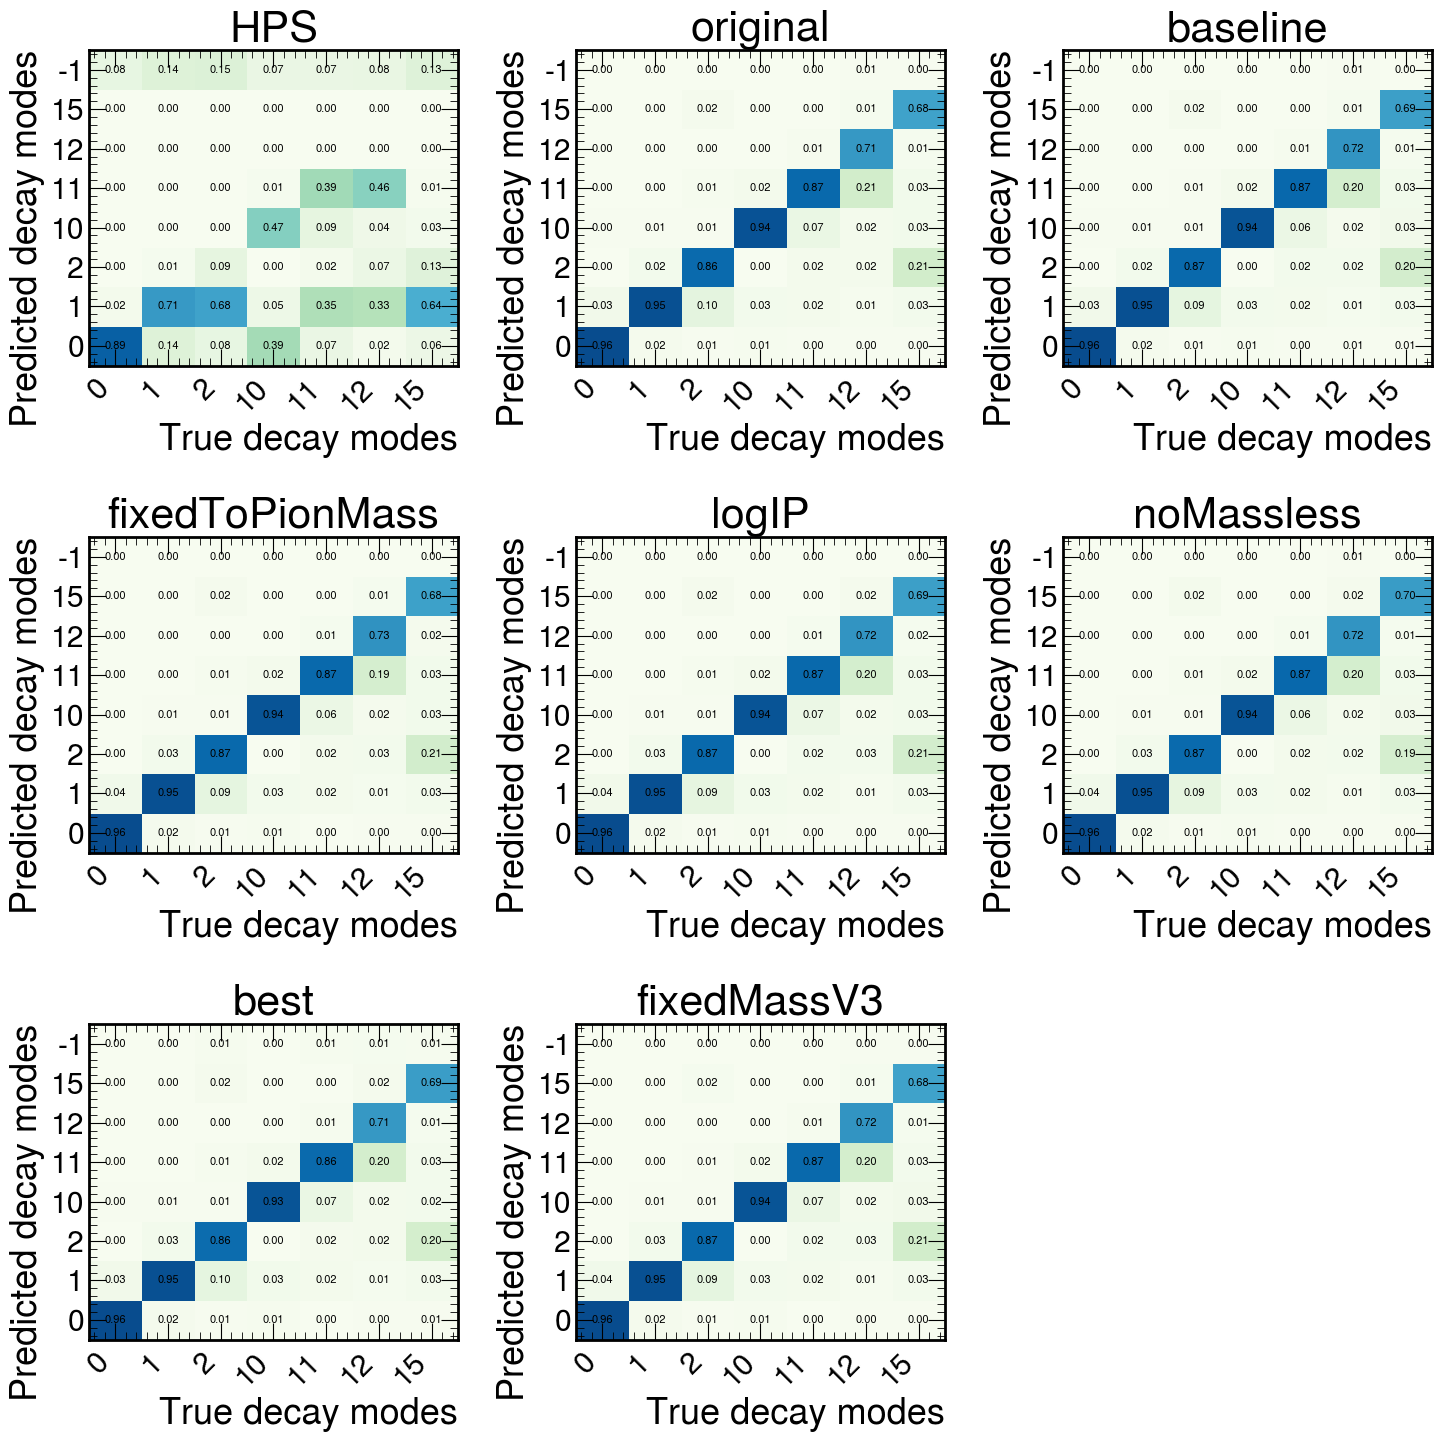

In [13]:
matrices = {"HPS": dh.construct_hps_confusion_matrix(truth, predicted, categories)}
for name, data in sts_runs.items():
    sts_truth = reduce_decay_modes(data.gen_jet_tau_decaymode, invalid_decay_mode=15)
    sts_predicted = reduce_decay_modes(data.tau_decaymode, invalid_decay_mode=-1)
    matrices[name] = dh.construct_hps_confusion_matrix(sts_truth, sts_predicted, categories)

ncols = min(3, len(matrices))
nrows = (len(matrices) + ncols - 1) // ncols
fig_dm, axes_dm = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
predicted_categories = [*categories, -1]
for ax, (name, matrix) in zip(axes_dm.flat, matrices.items()):
    ax.imshow(matrix.T, origin="lower", vmin=0, vmax=1, cmap="GnBu", aspect="auto")
    ax.set_title(name)
    ax.set_xticks(range(len(categories)), categories, rotation=45, ha="right")
    ax.set_yticks(range(len(predicted_categories)), predicted_categories)
    ax.set_xlabel("True decay modes")
    ax.set_ylabel("Predicted decay modes")
    for row in range(len(predicted_categories)):
        for col in range(len(categories)):
            ax.text(col, row, f"{matrix[col, row]:.2f}", ha="center", va="center", fontsize=8)
for ax in list(axes_dm.flat)[len(matrices):]:
    ax.set_visible(False)
fig_dm.tight_layout()
fig_dm.savefig(os.path.join(output_dir, "decay_modes_all_runs.pdf"), dpi=300, bbox_inches="tight")
display(fig_dm)
plt.close(fig_dm)

In [14]:
from mltau.tools.evaluation import kinematics as k

In [15]:
from omegaconf import OmegaConf, open_dict

hps_ke = k.KinematicsEvaluator(
    predicted_p4=hps_data.tau_p4s,
    true_p4=hps_data.gen_jet_tau_p4,
    cfg=cfg,
    algorithm="HPS",
    sample_name="z",
)

sts_evaluators = []
line_styles = ["solid", "dashed", "dashdot", "dotted"]
run_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]
for index, (name, data) in enumerate(sts_runs.items()):
    with open_dict(cfg.metrics.ALGORITHM_PLOT_STYLES):
        cfg.metrics.ALGORITHM_PLOT_STYLES[name] = OmegaConf.create(
            OmegaConf.to_container(cfg.metrics.ALGORITHM_PLOT_STYLES.STS, resolve=True)
        )
    style = cfg.metrics.ALGORITHM_PLOT_STYLES[name]
    style.name = name
    style.color = run_colors[index % len(run_colors)]
    style.ls = line_styles[index % len(line_styles)]
    sts_evaluators.append(k.KinematicsEvaluator(
        predicted_p4=data.tau_p4,
        true_p4=data.gen_jet_tau_p4,
        cfg=cfg,
        algorithm=name,
        sample_name="z",
    ))

reference_data = next(iter(sts_runs.values()))
rj_ke = k.KinematicsEvaluator(
    predicted_p4=reference_data.reco_jet_p4,
    true_p4=reference_data.gen_jet_tau_p4,
    cfg=cfg,
    algorithm="RecoJet",
    sample_name="z",
)

/home/karl/ml-tau-model/mltau/tools/evaluation/kinematics.py:255: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, rows = plt.subplots(nrows=3, ncols=4, sharex="col", figsize=(16, 9))
/opt/conda/lib/python3.11/site-packages/mplhep/utils.py:720: RuntimeWarning: divide by zero encountered in scalar divide
  return self.flat_scale(1 / np.sum(np.diff(self.edges_1d()) * self.values()))
/opt/conda/lib/python3.11/site-packages/mplhep/utils.py:652: RuntimeWarning: All sumw are zero!  Cannot compute meaningful error bars
  return np.abs(method_fcn(self.values(), variances) - self.values())
/opt/conda/lib/python3.11/site-packages/mplhep/utils.py:703: RuntimeWarning: invalid value encountered in multiply
  self._values *= scale
/o

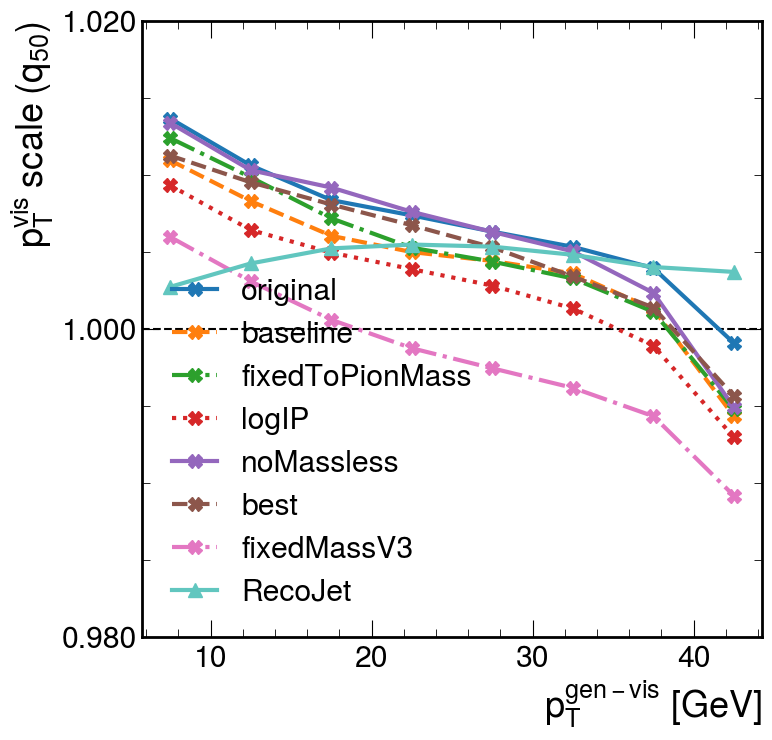

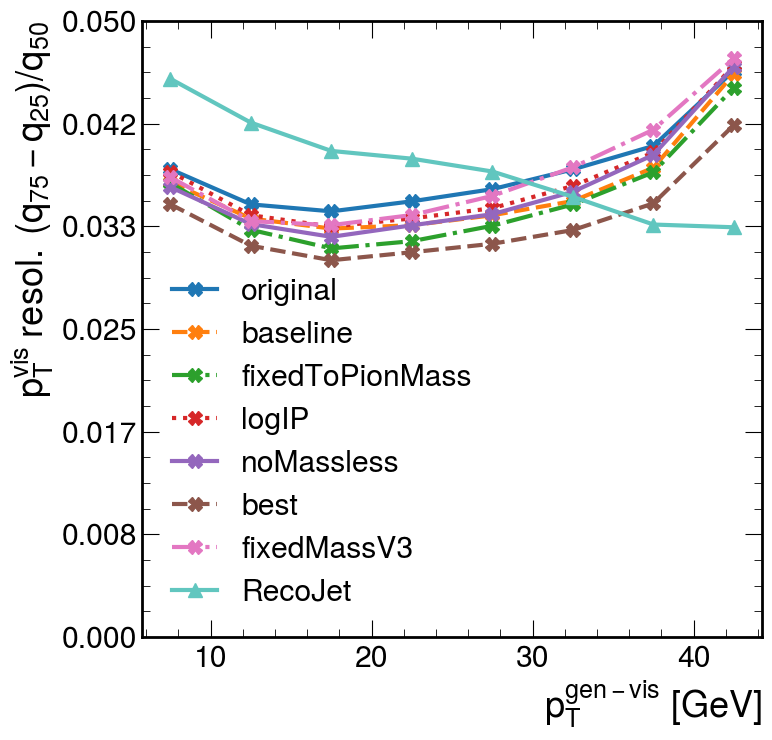

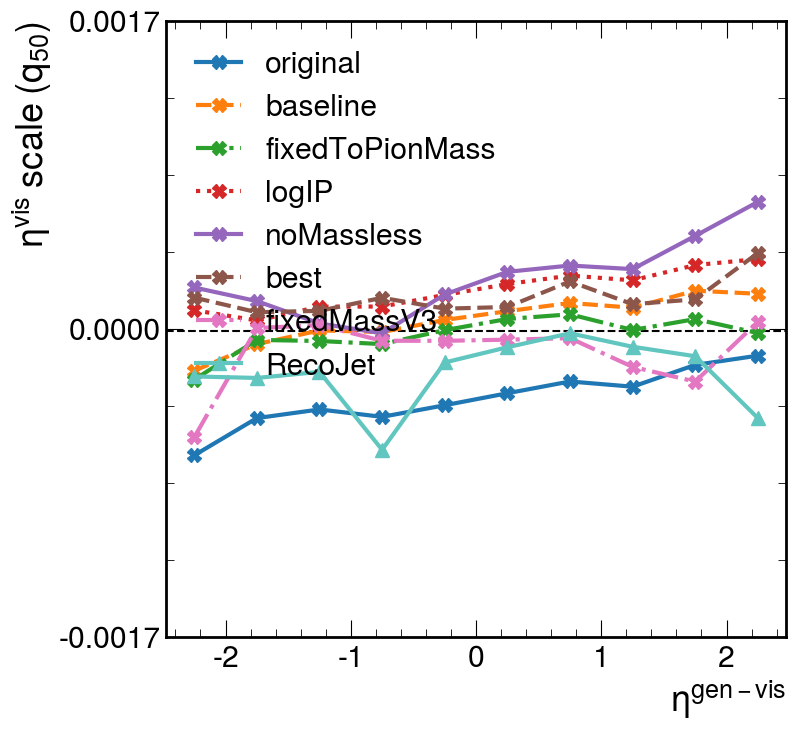

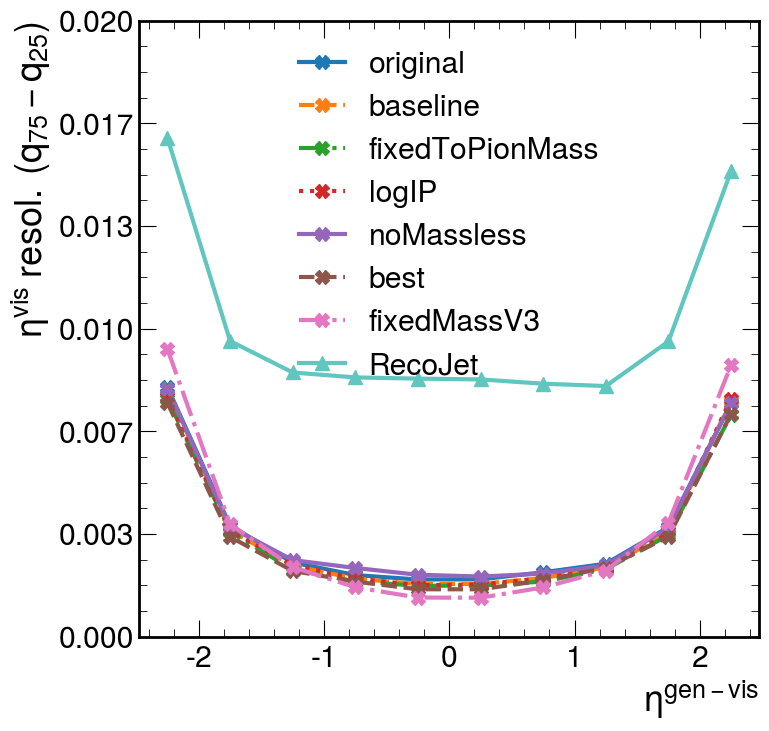

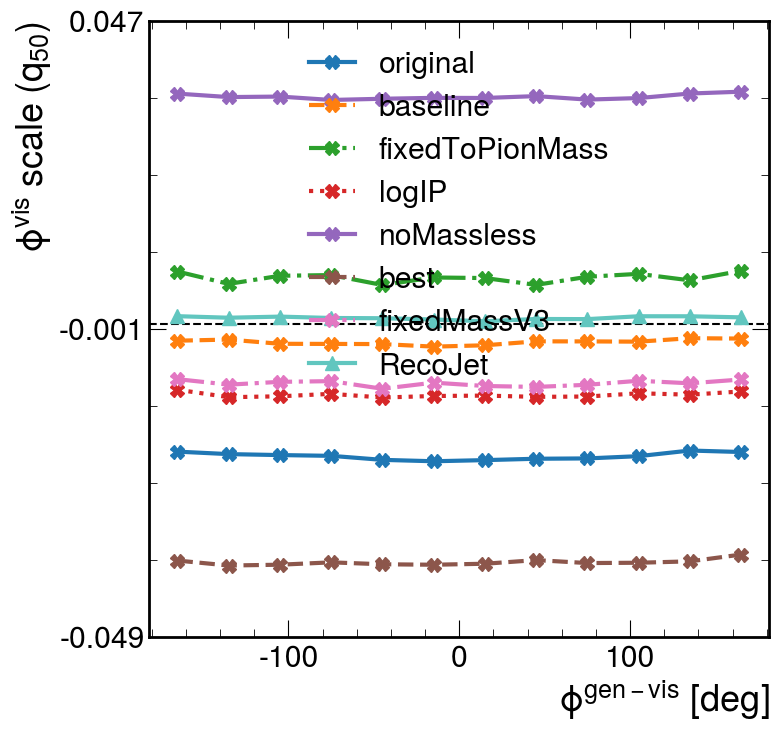

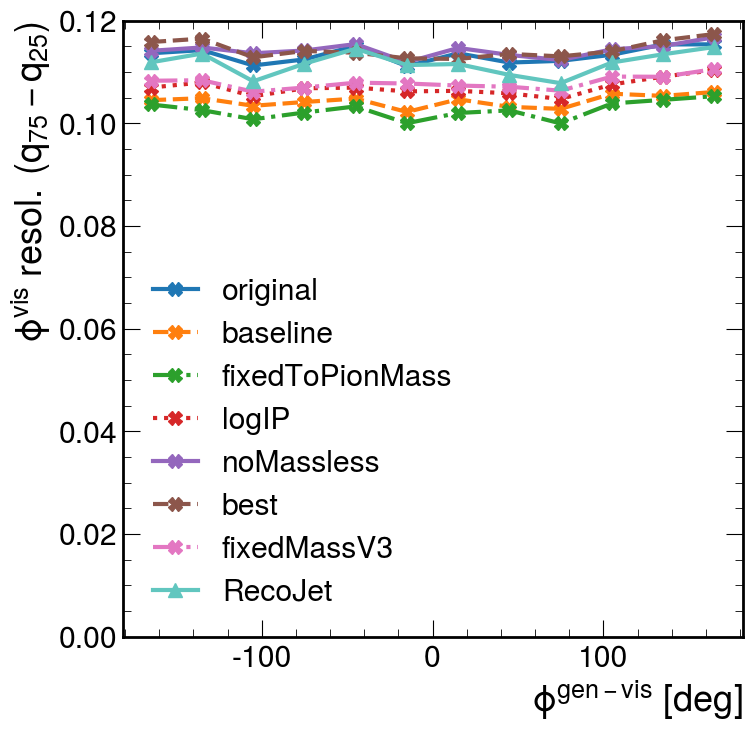

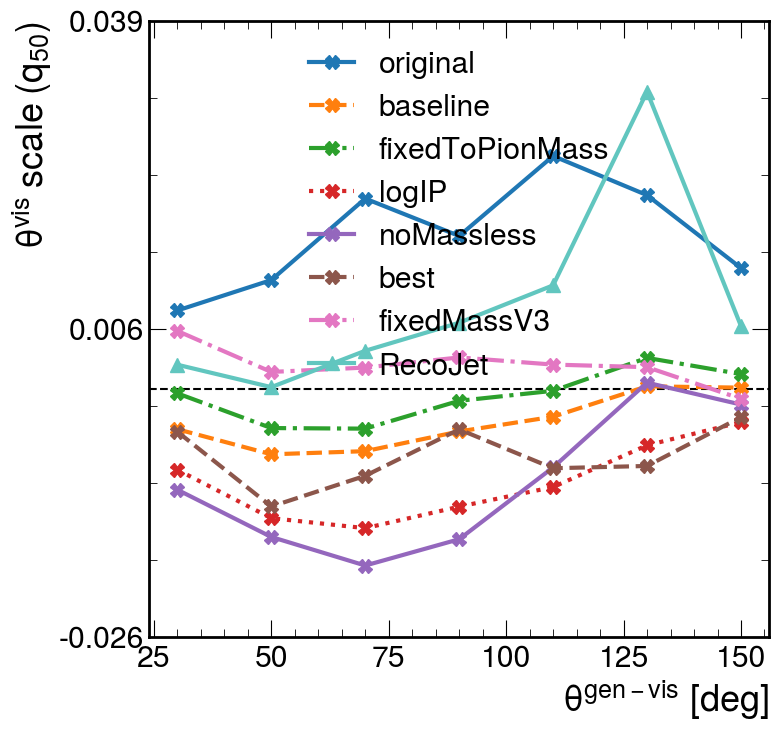

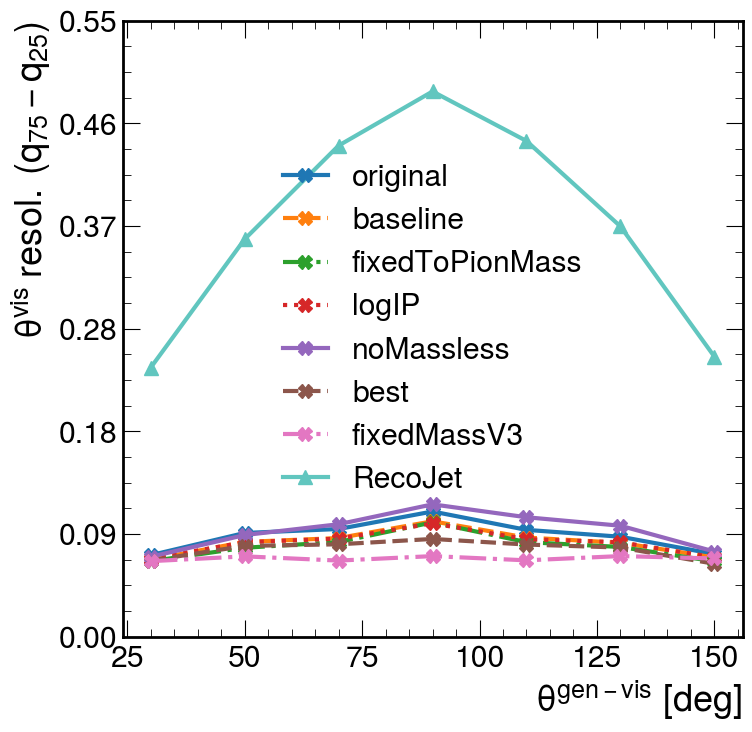

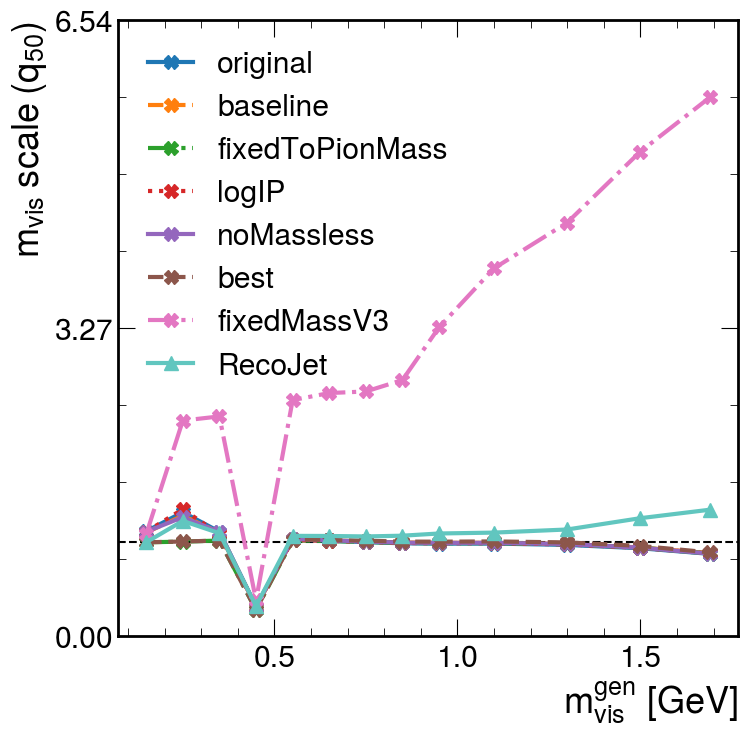

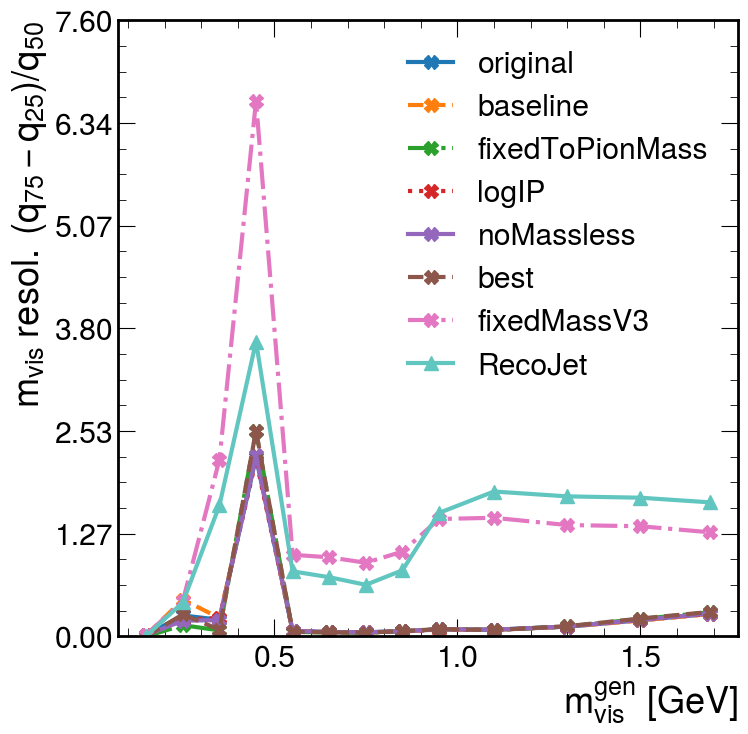

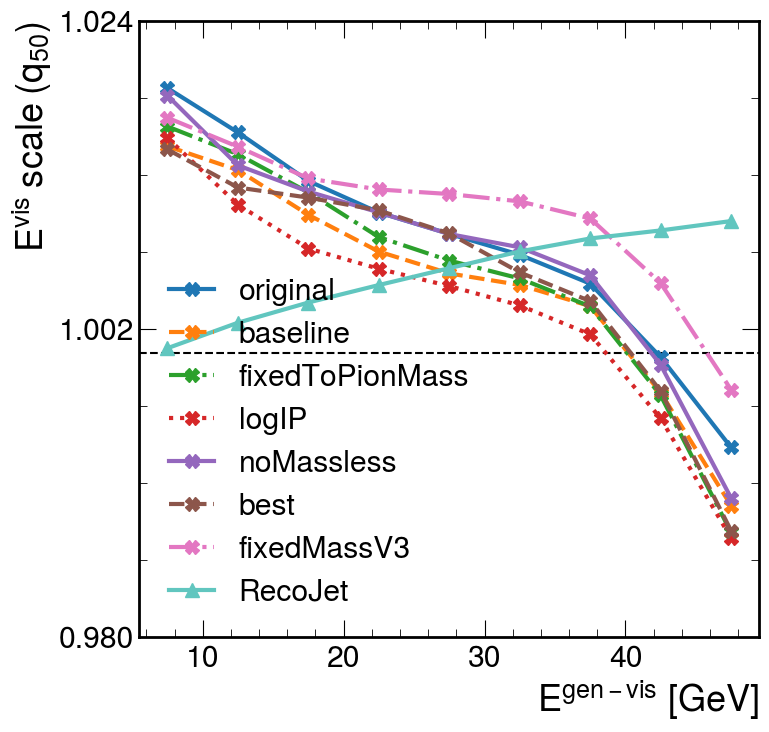

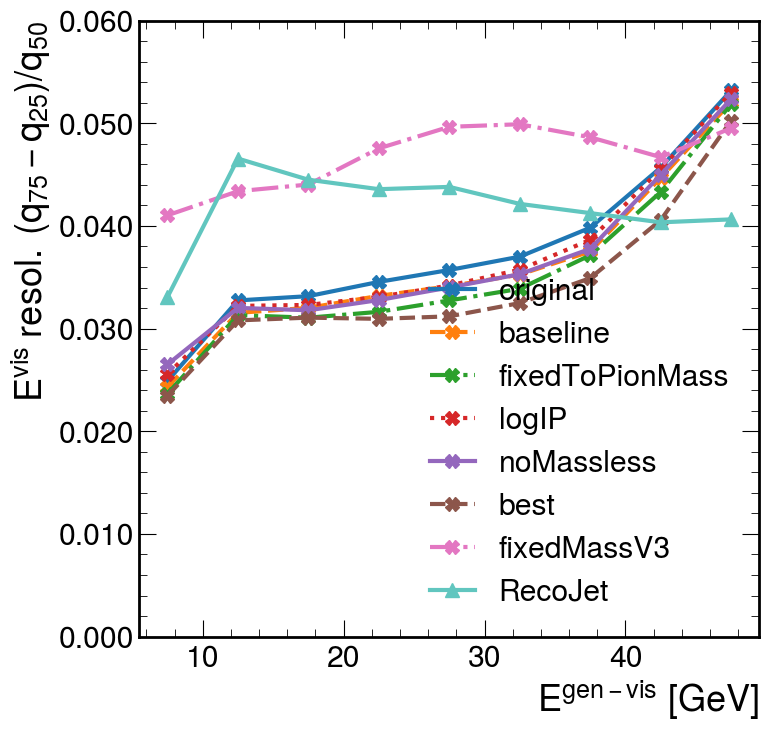

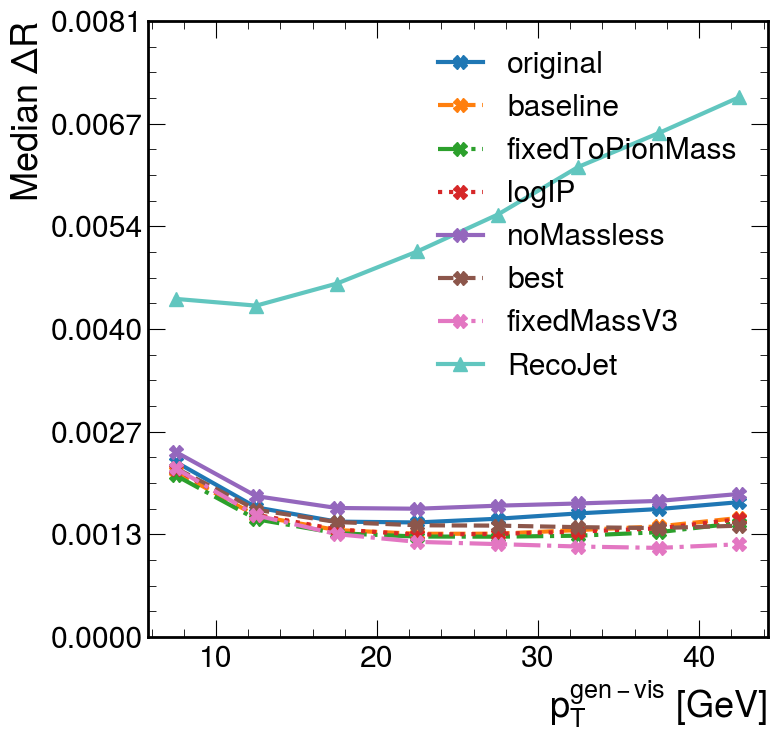

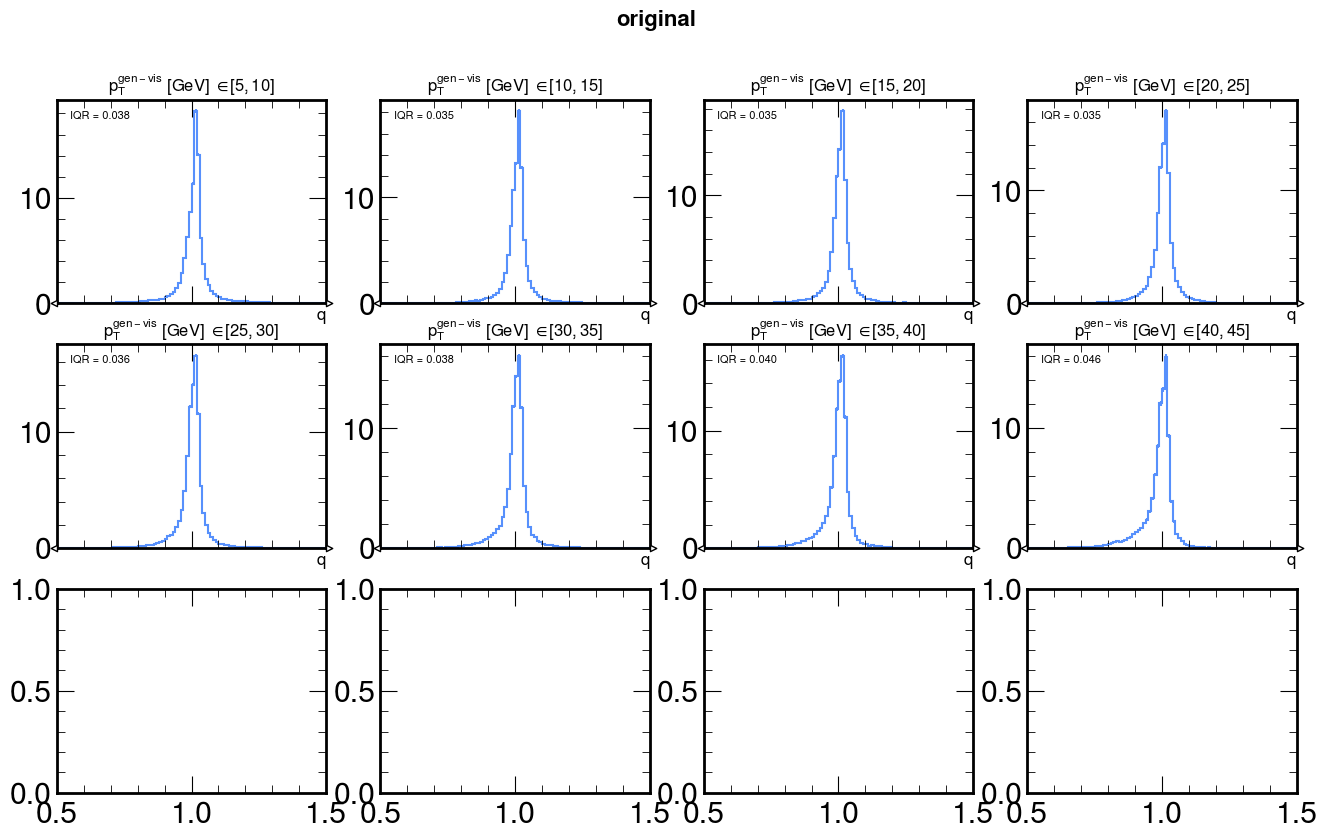

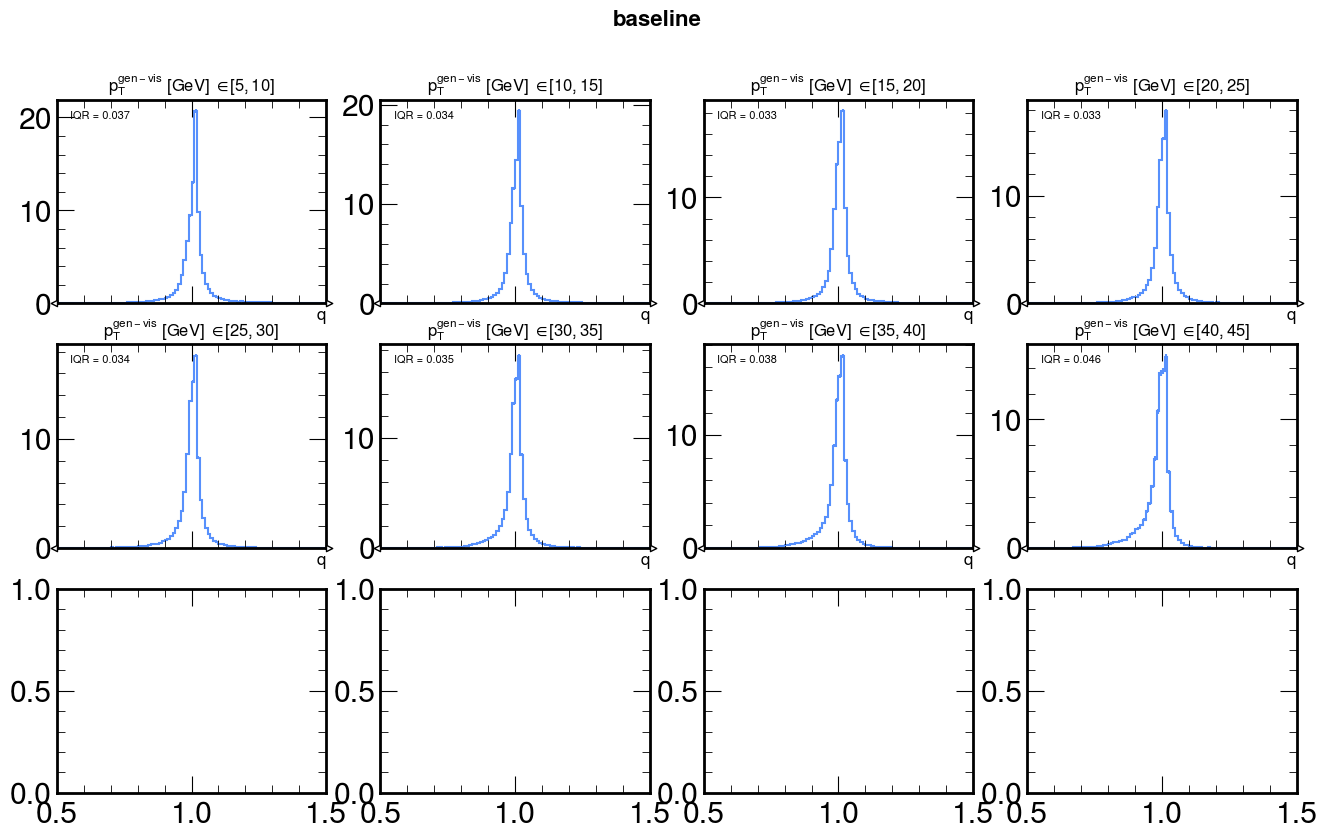

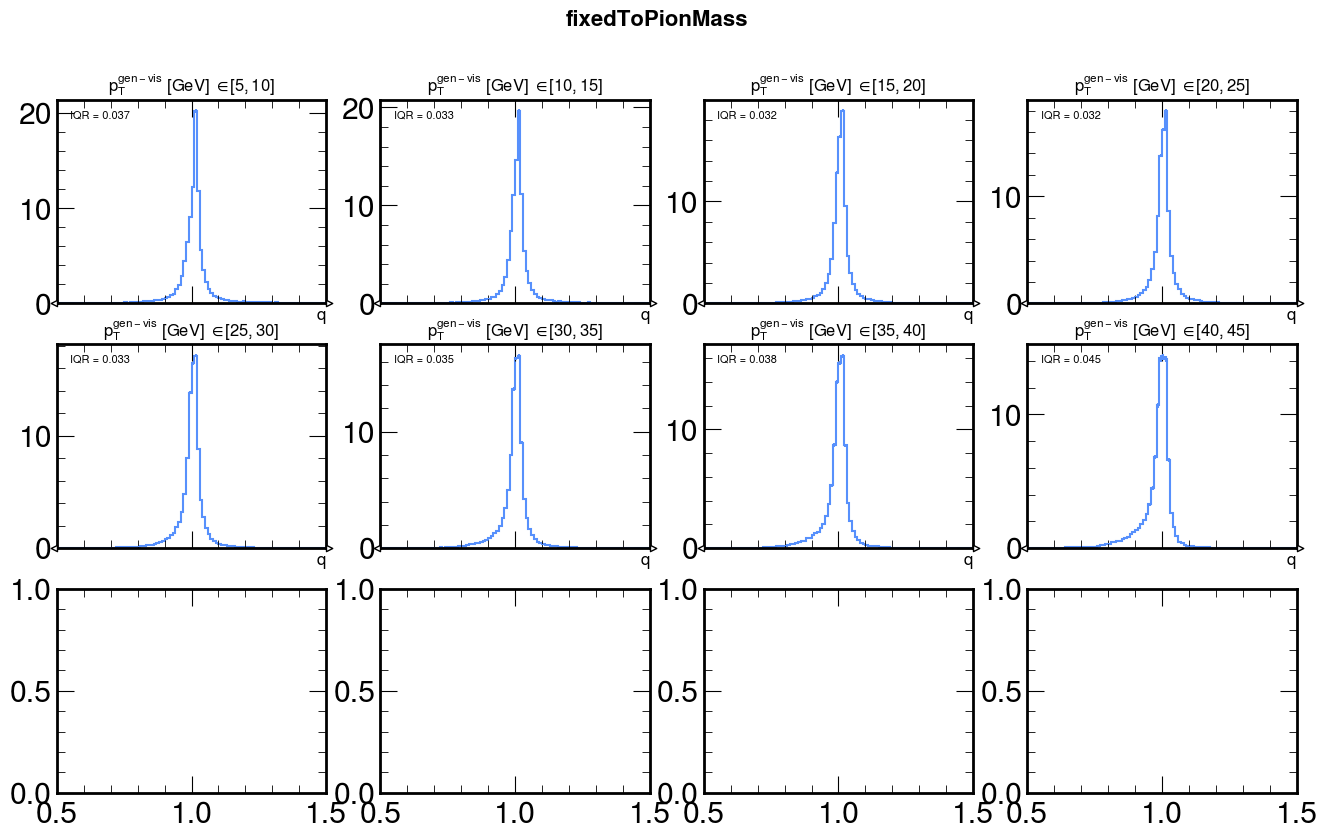

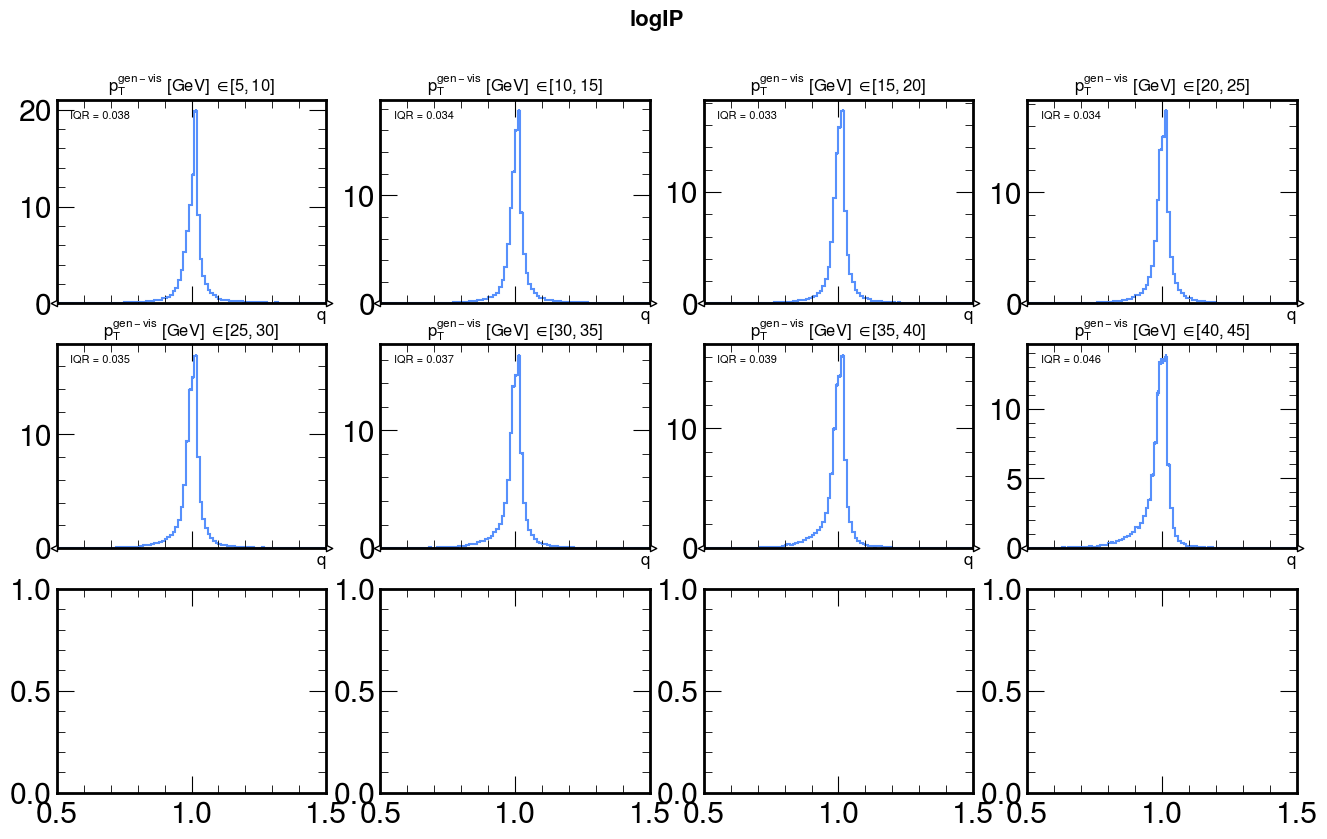

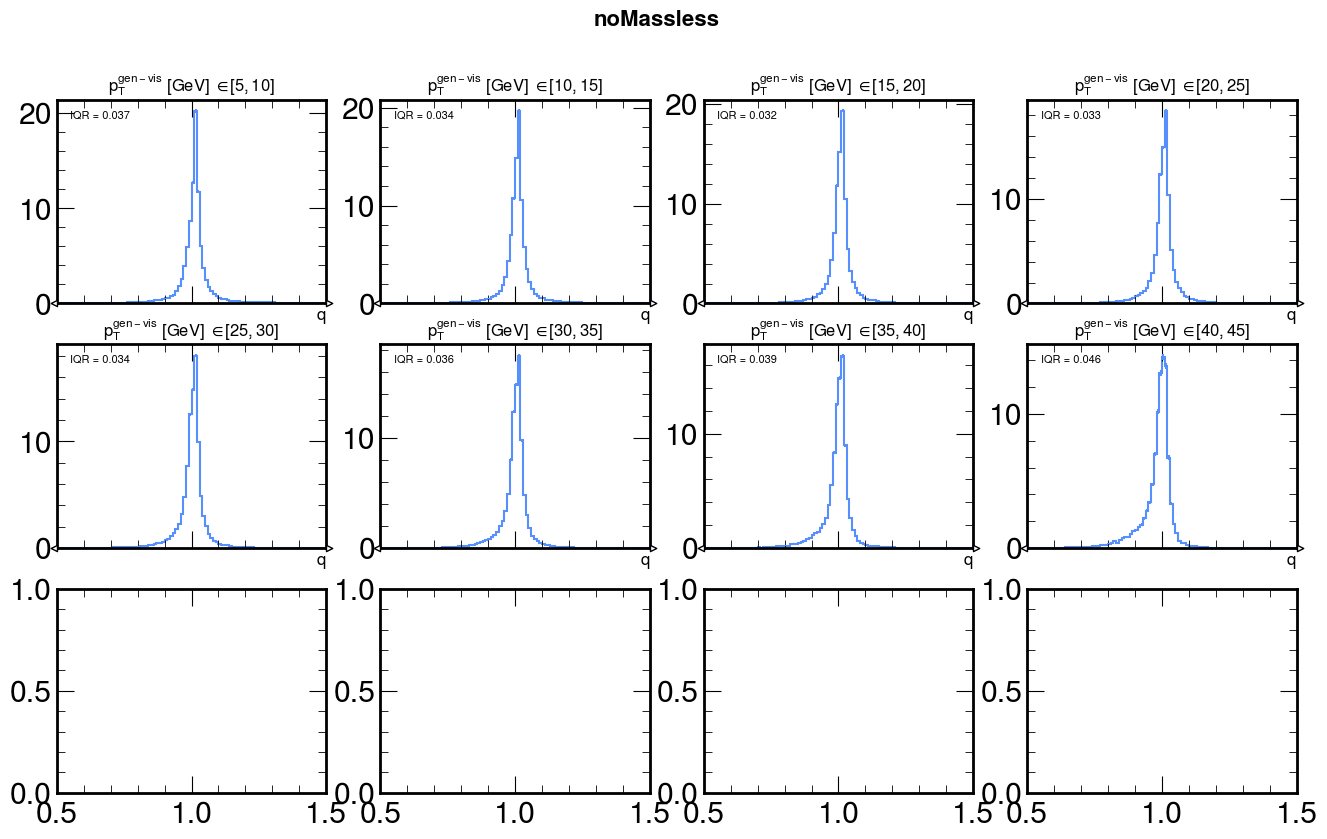

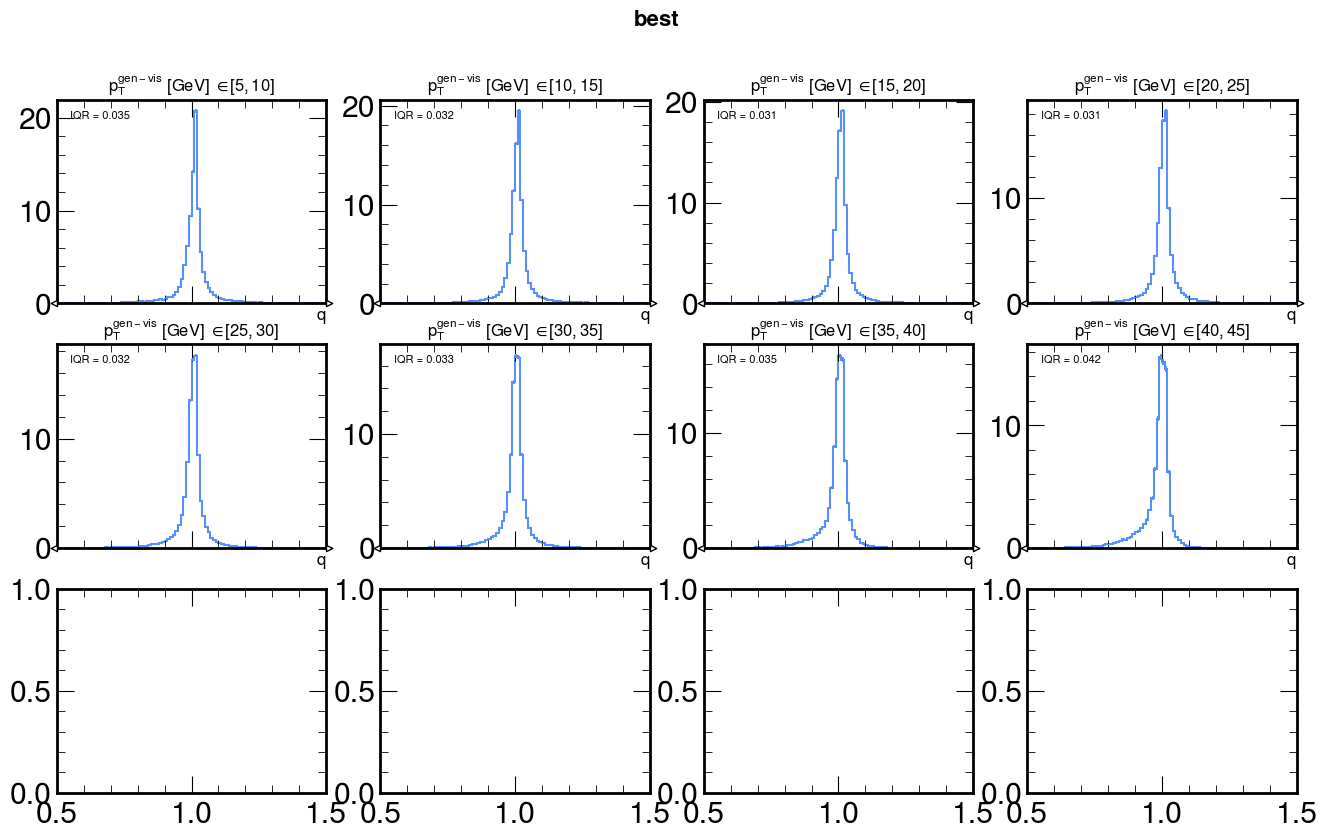

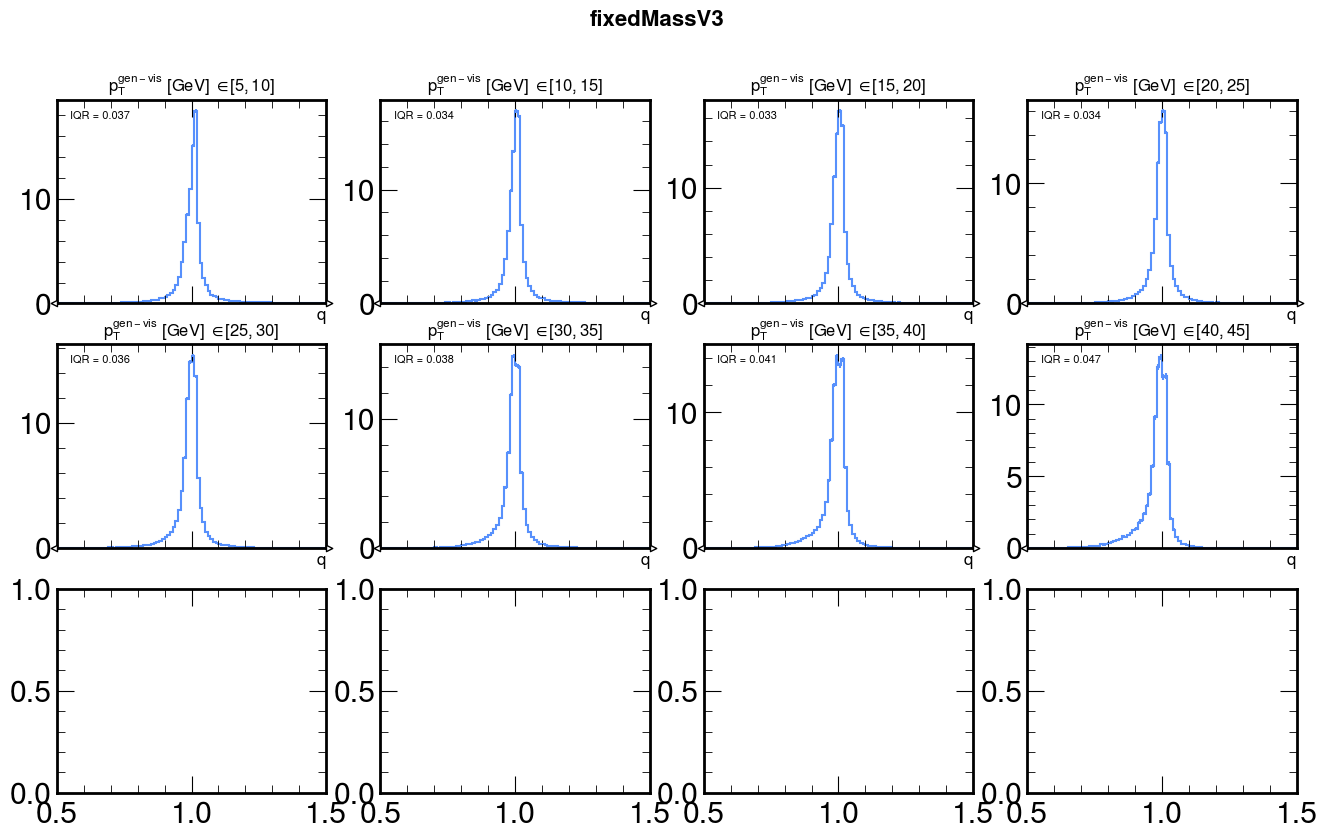

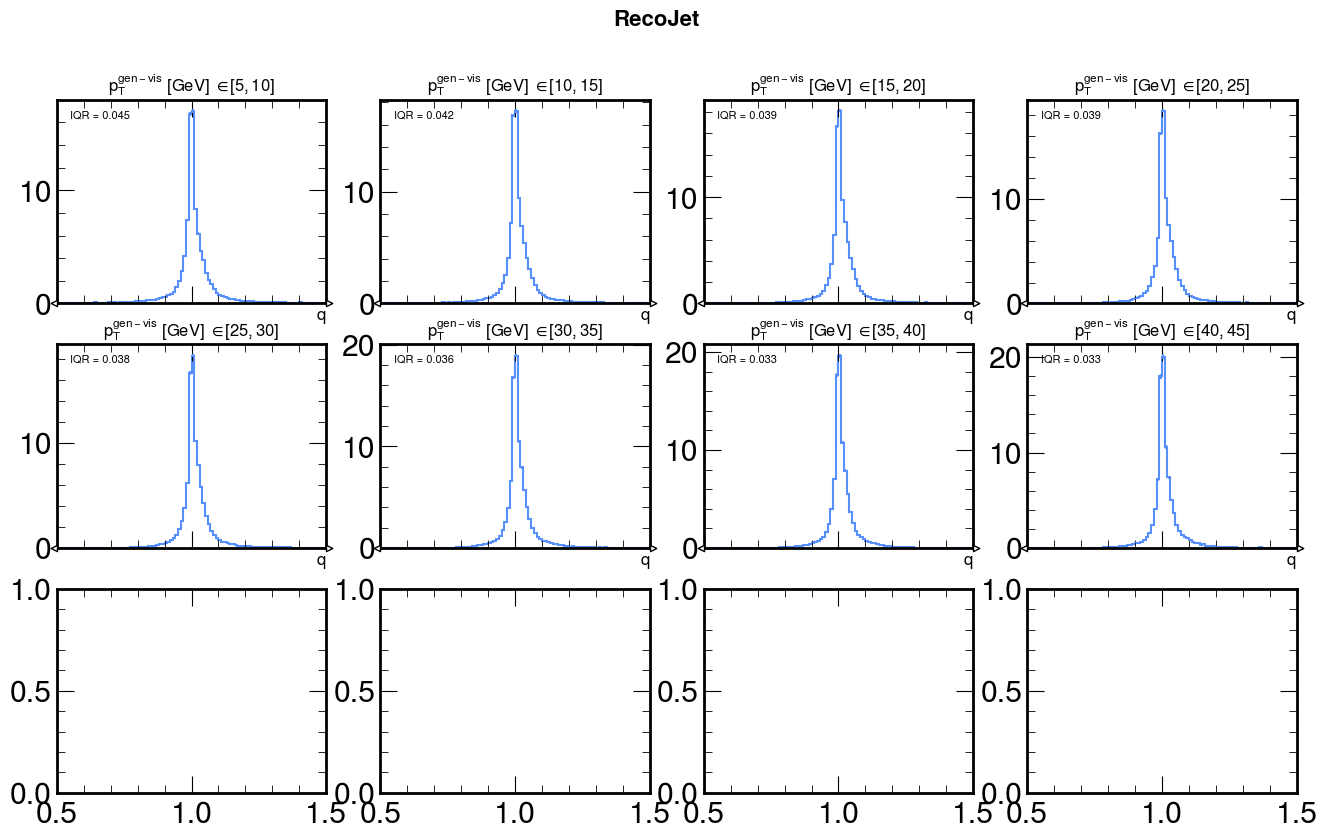

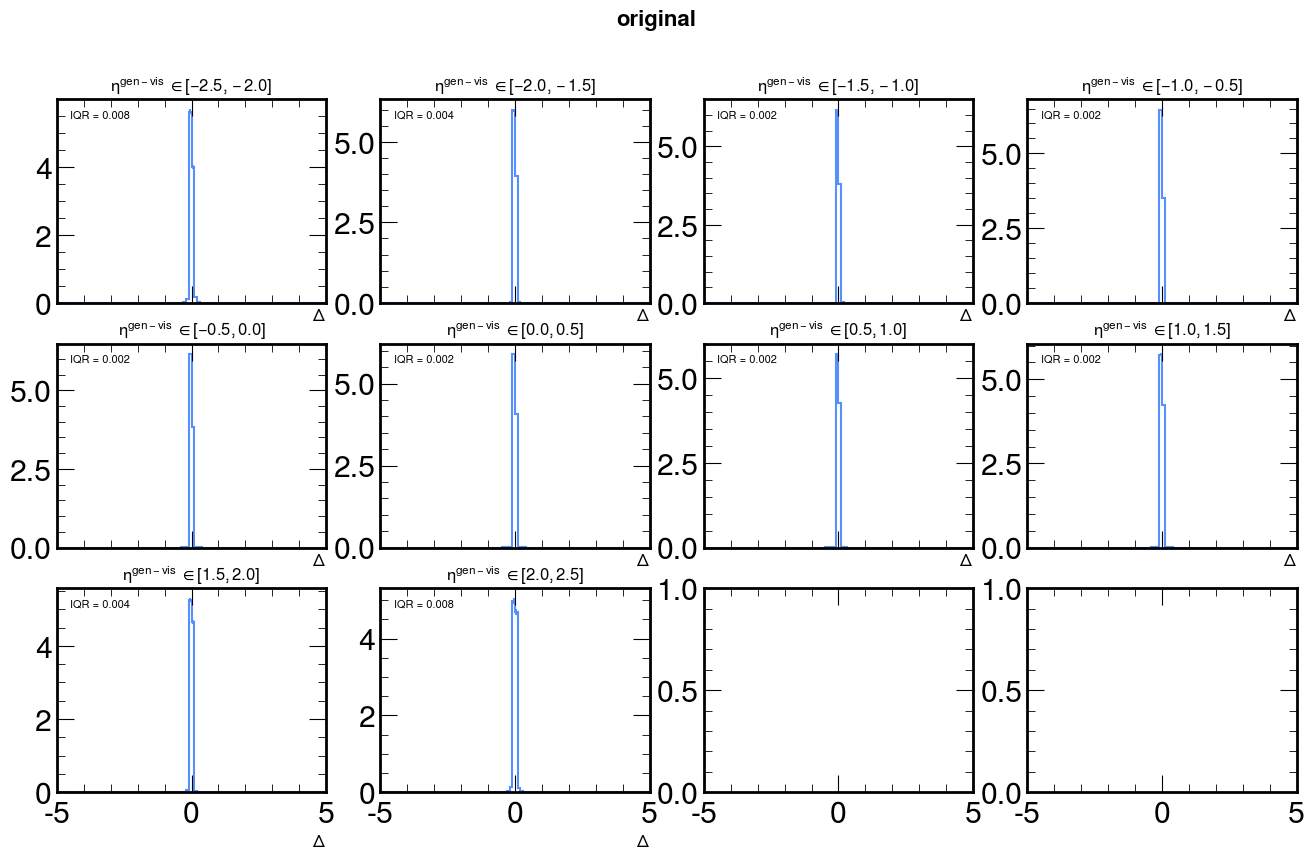

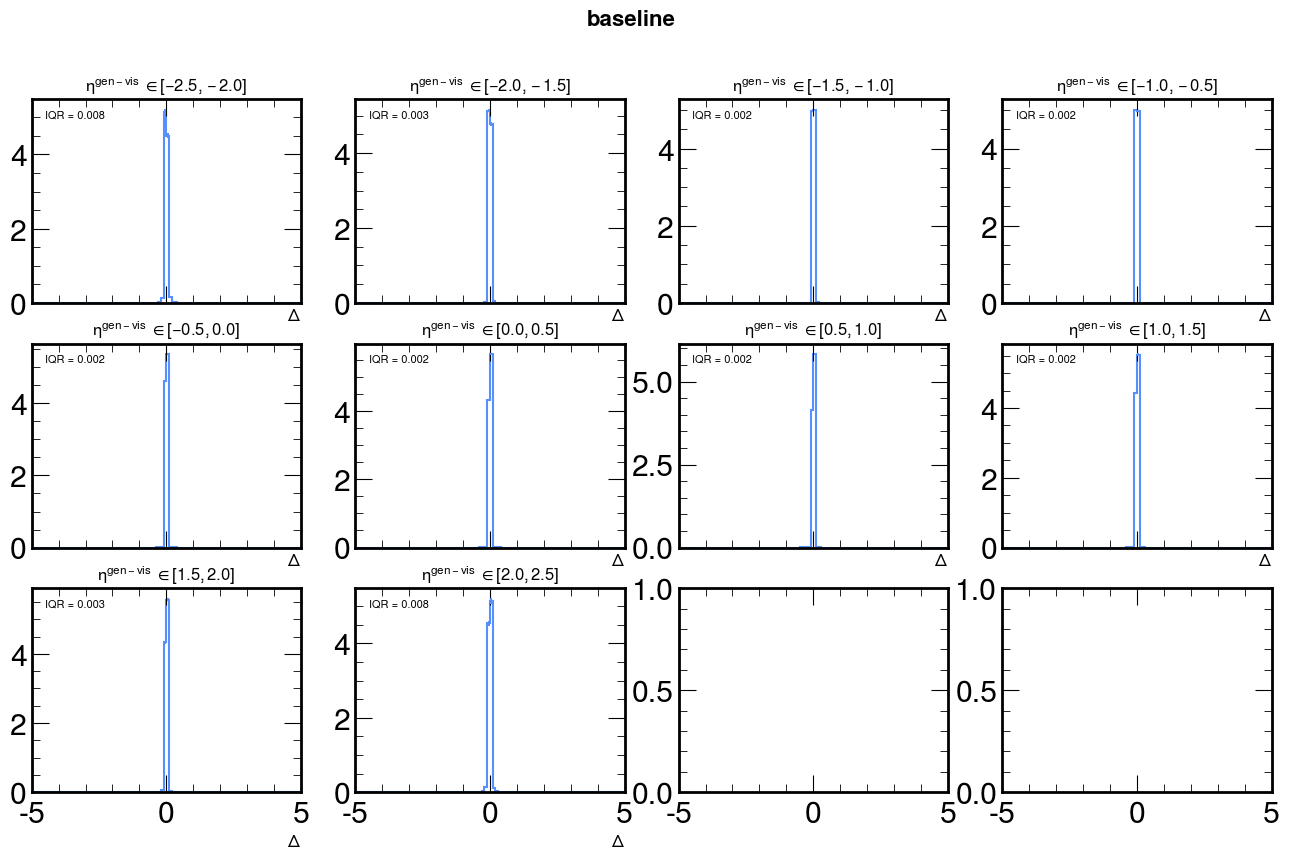

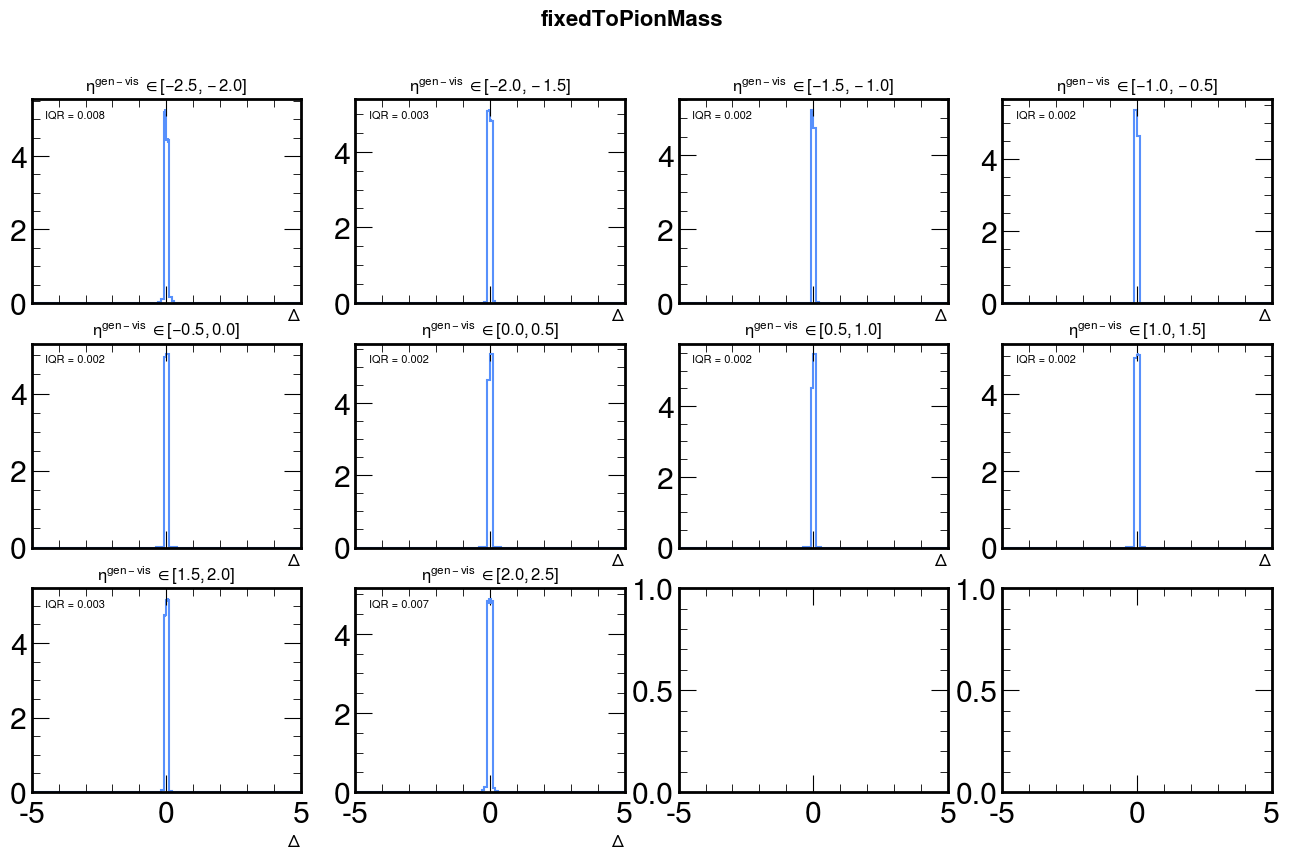

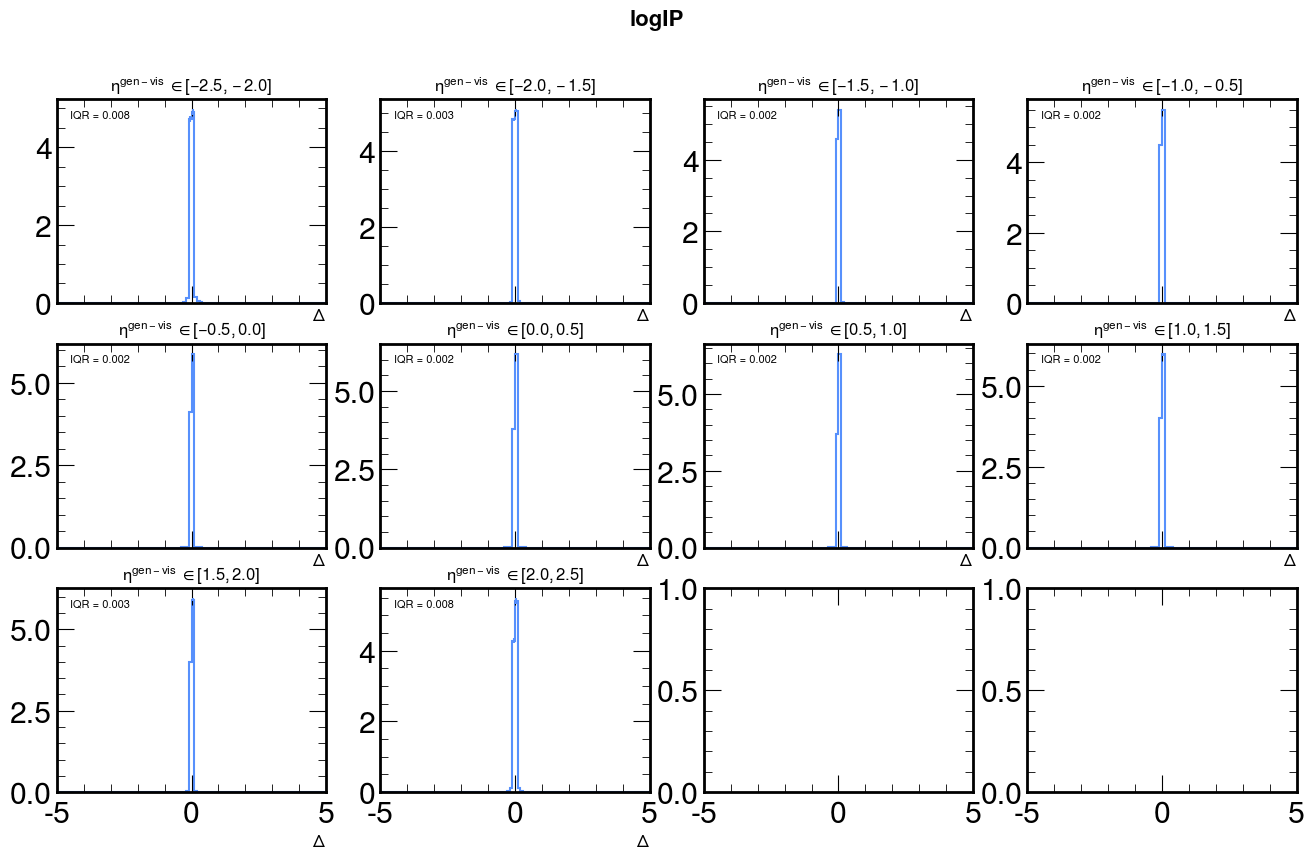

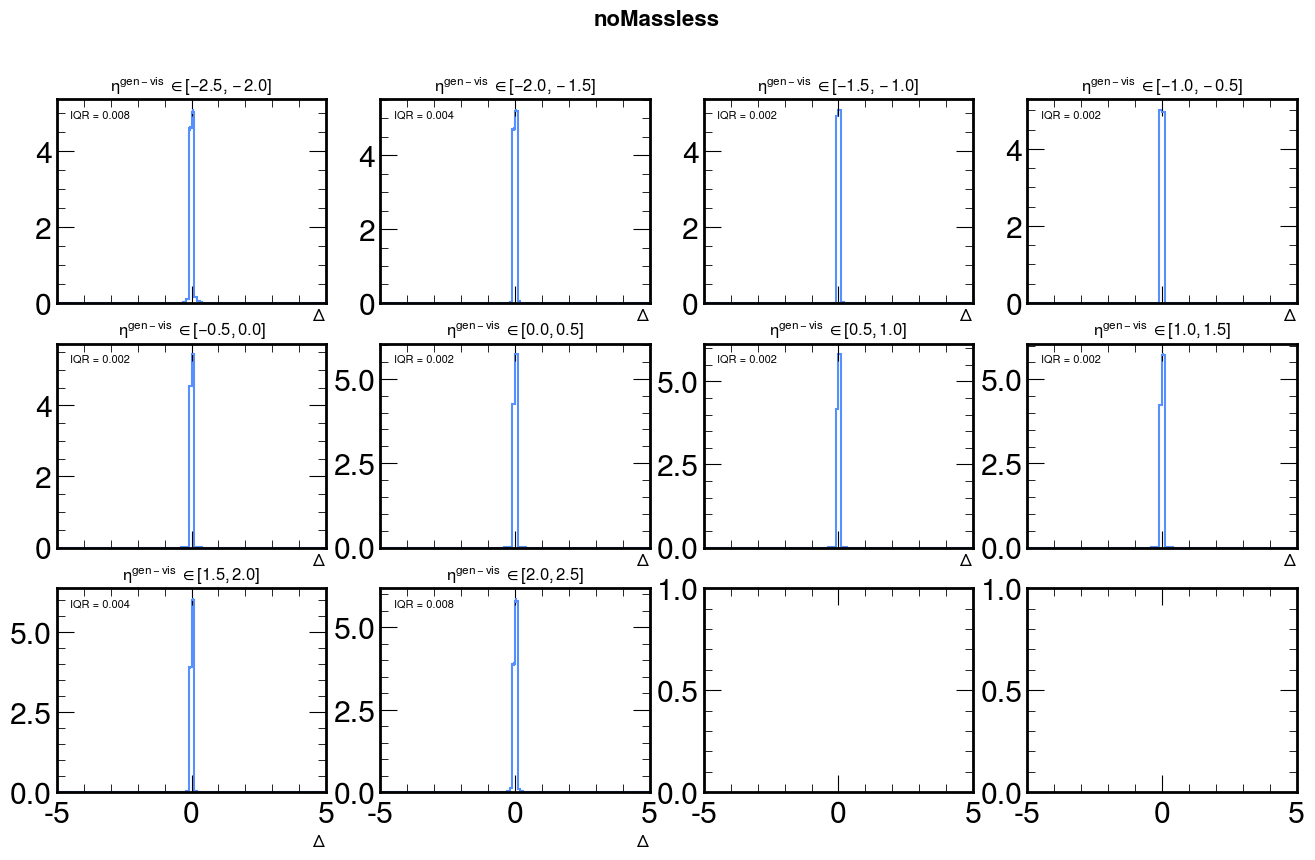

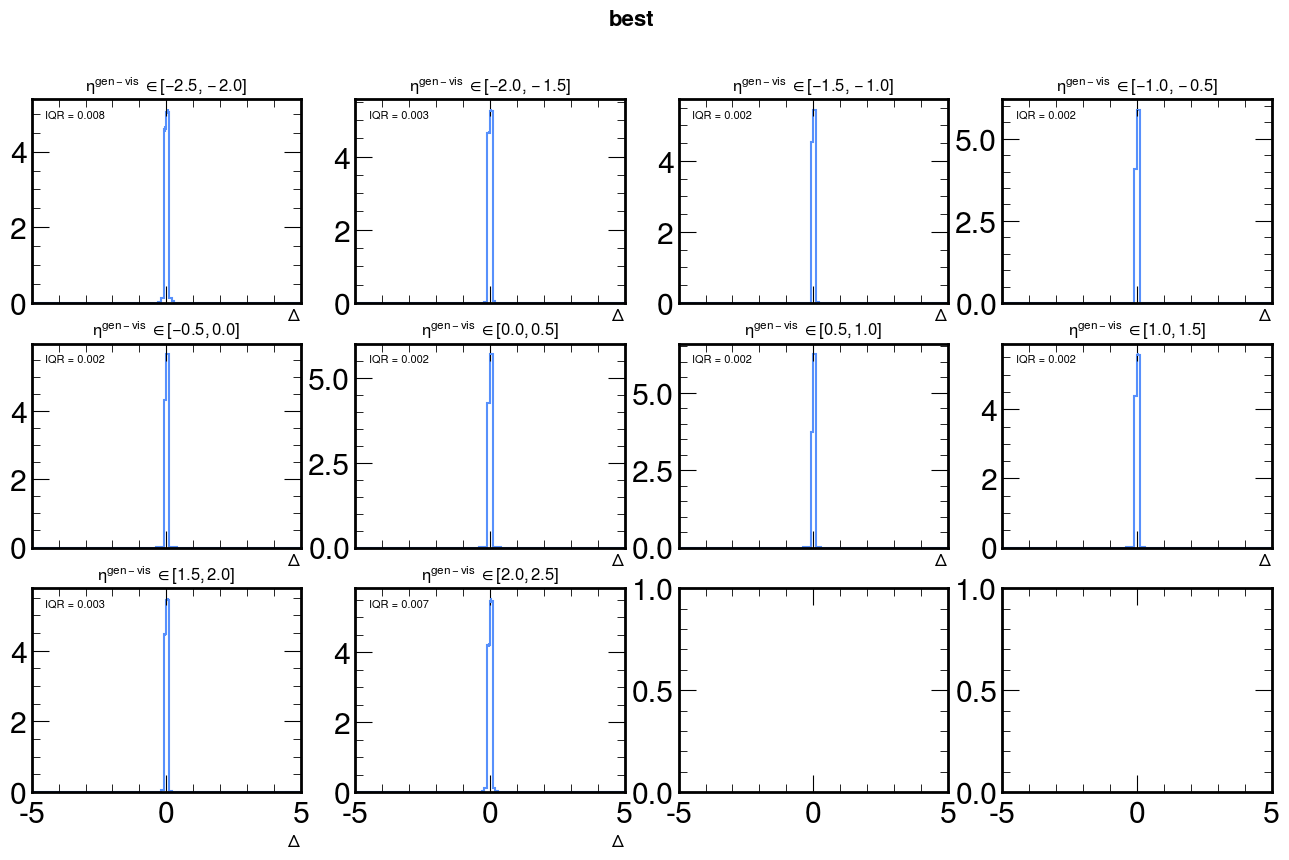

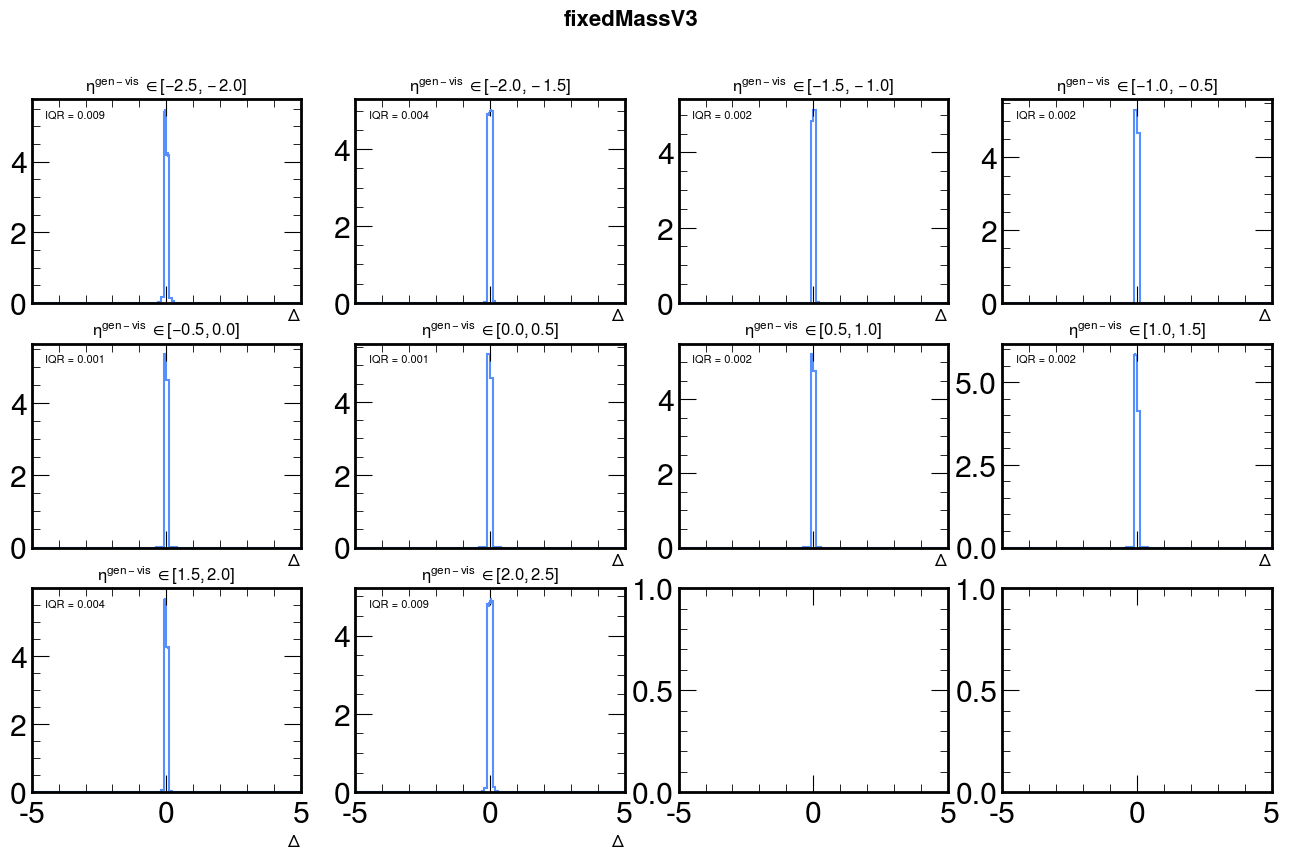

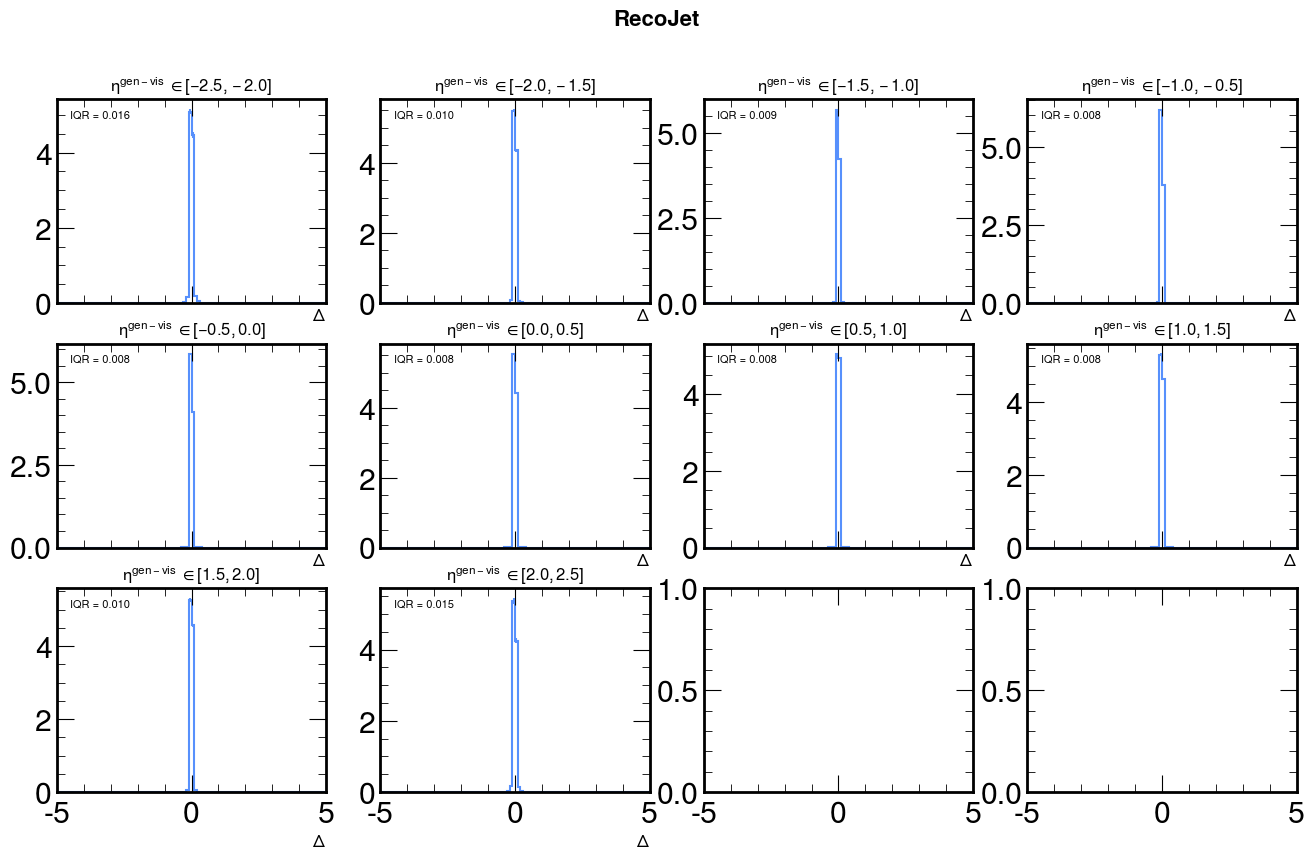

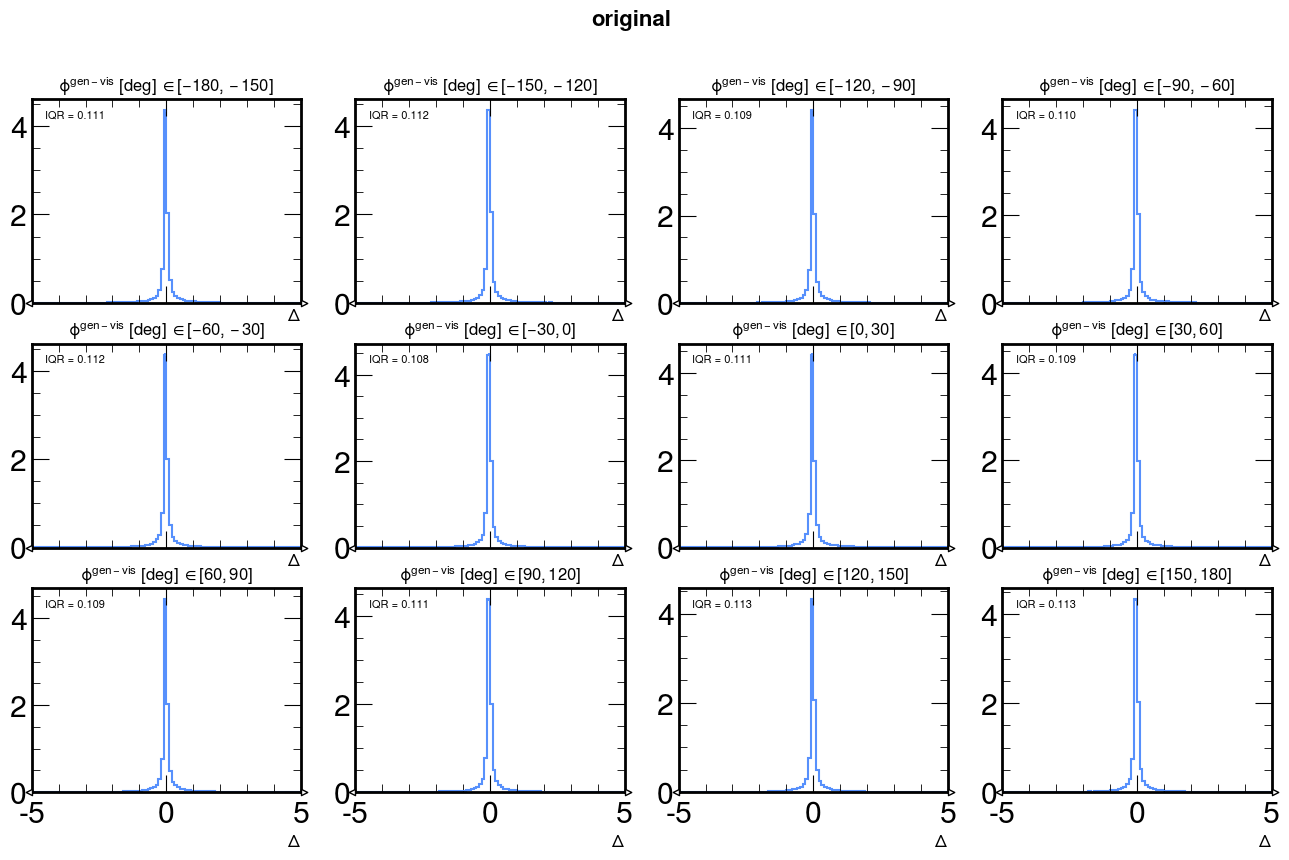

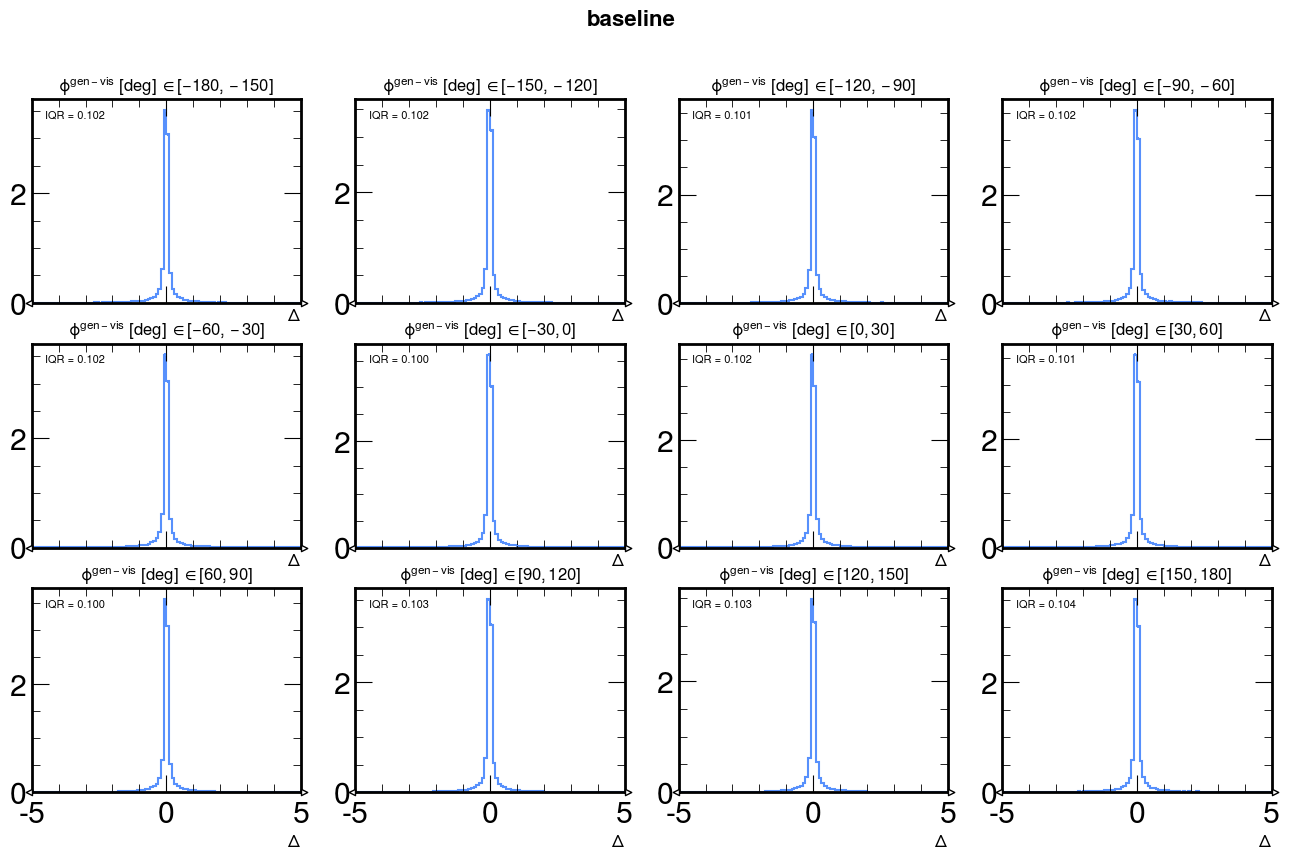

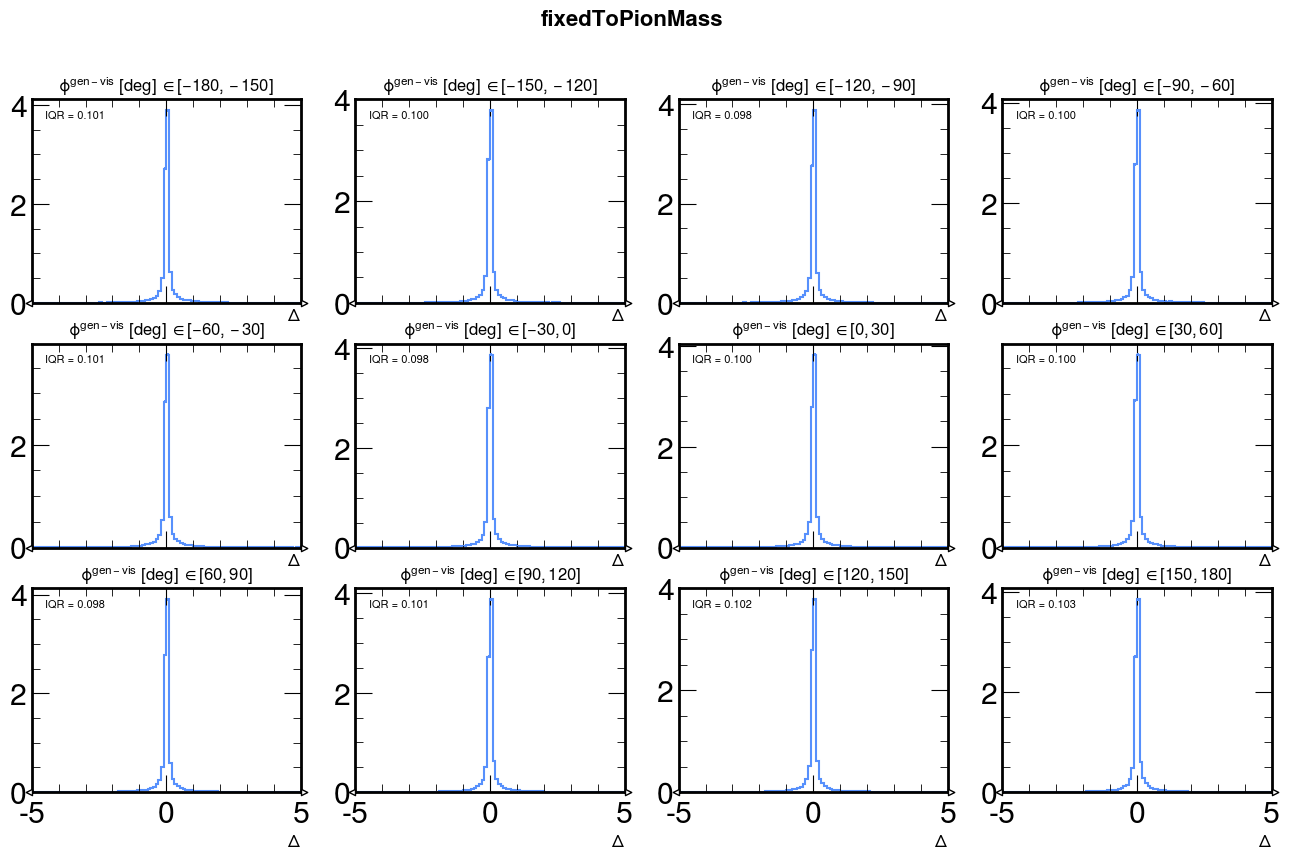

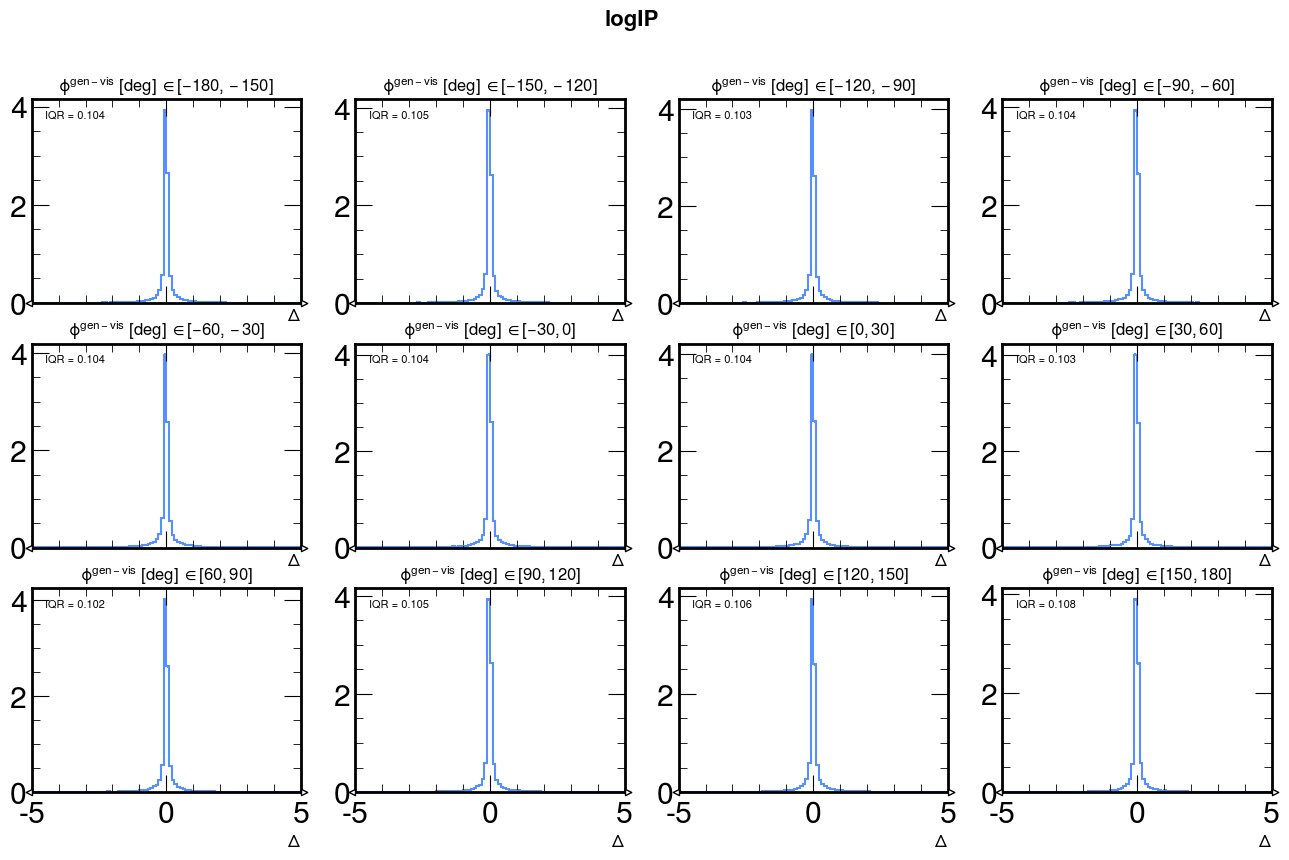

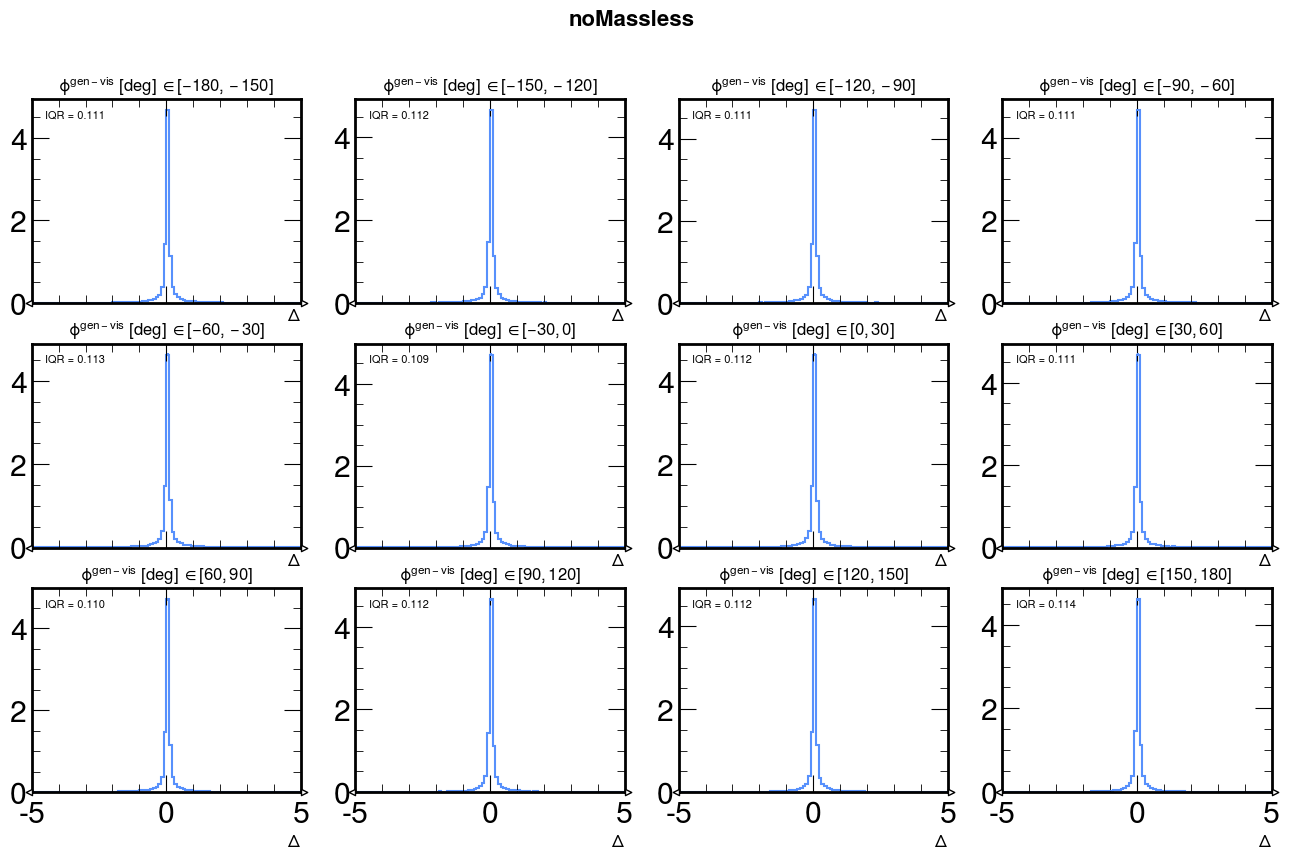

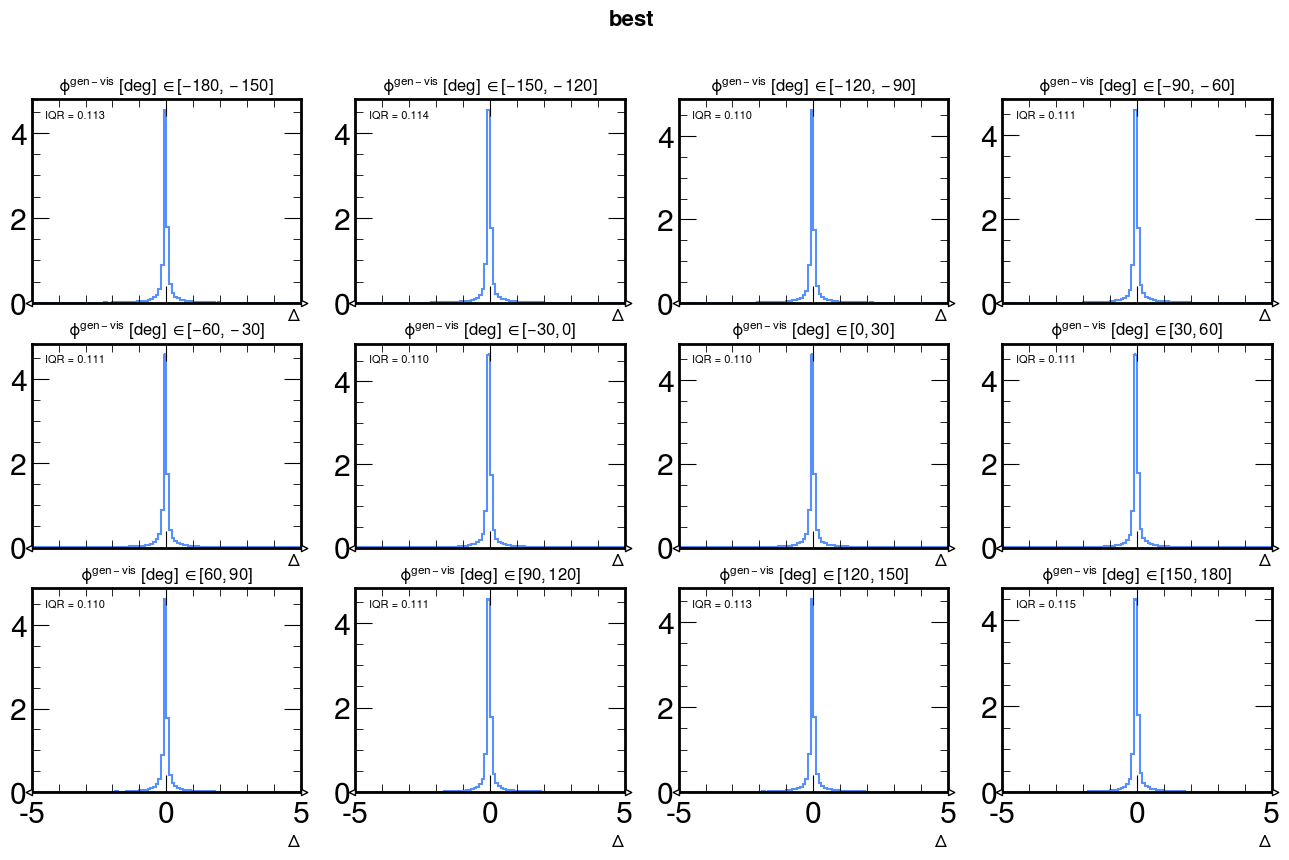

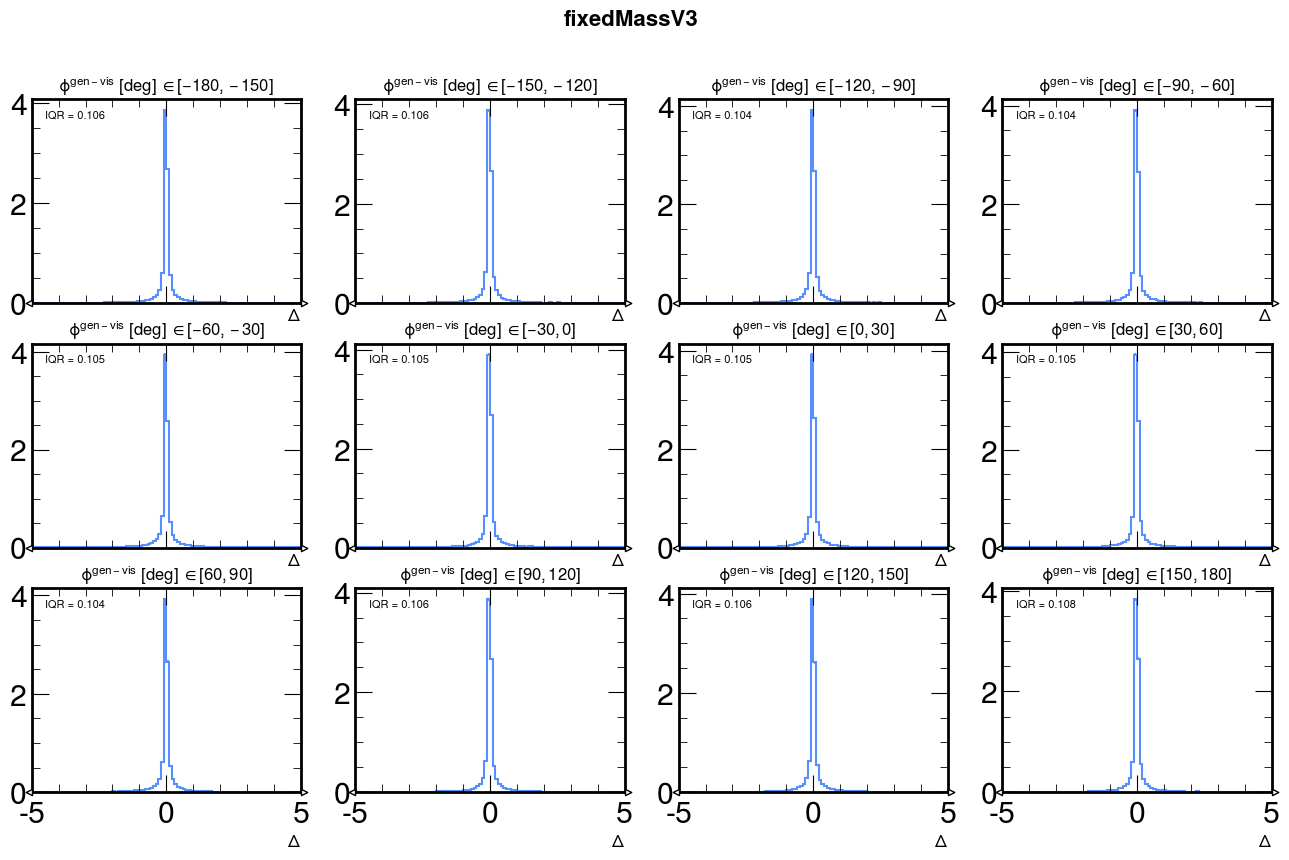

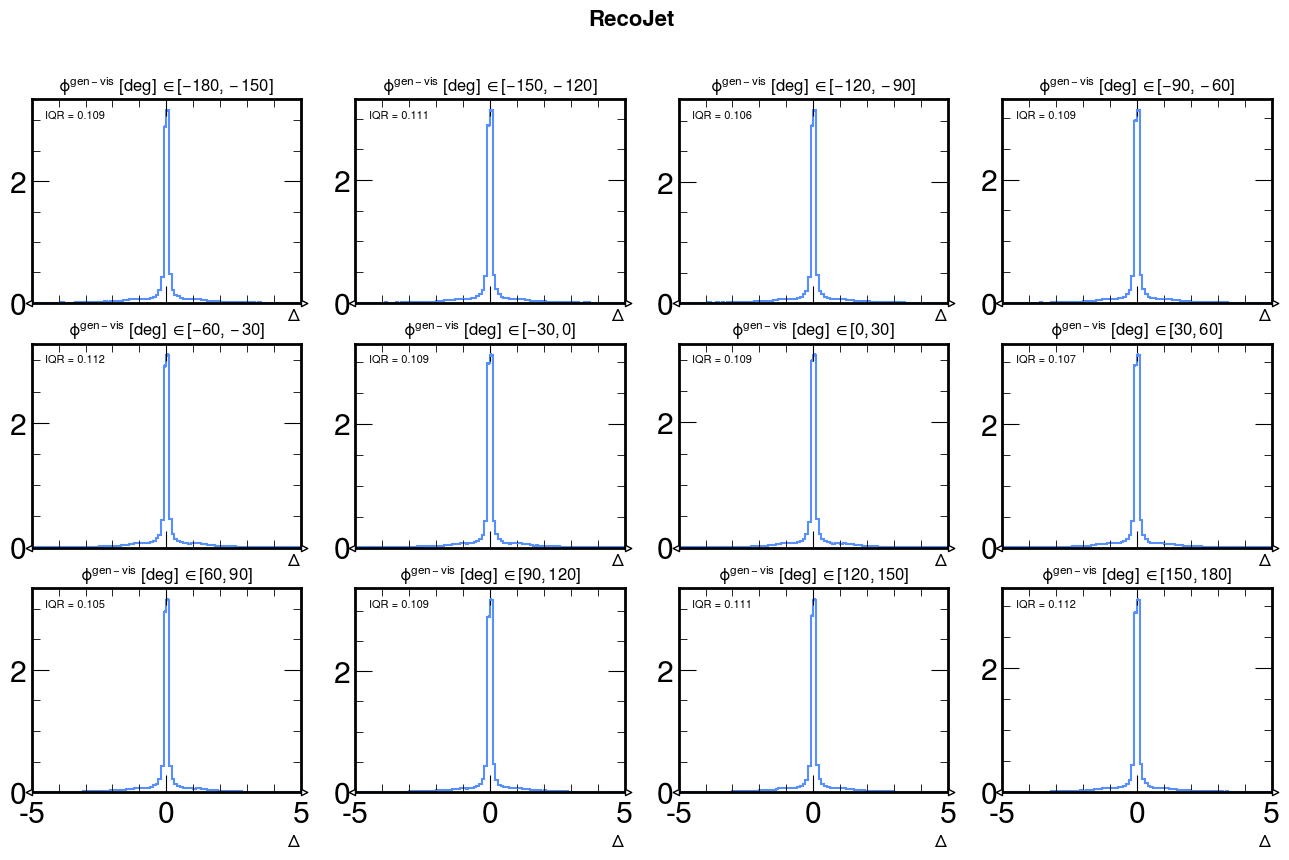

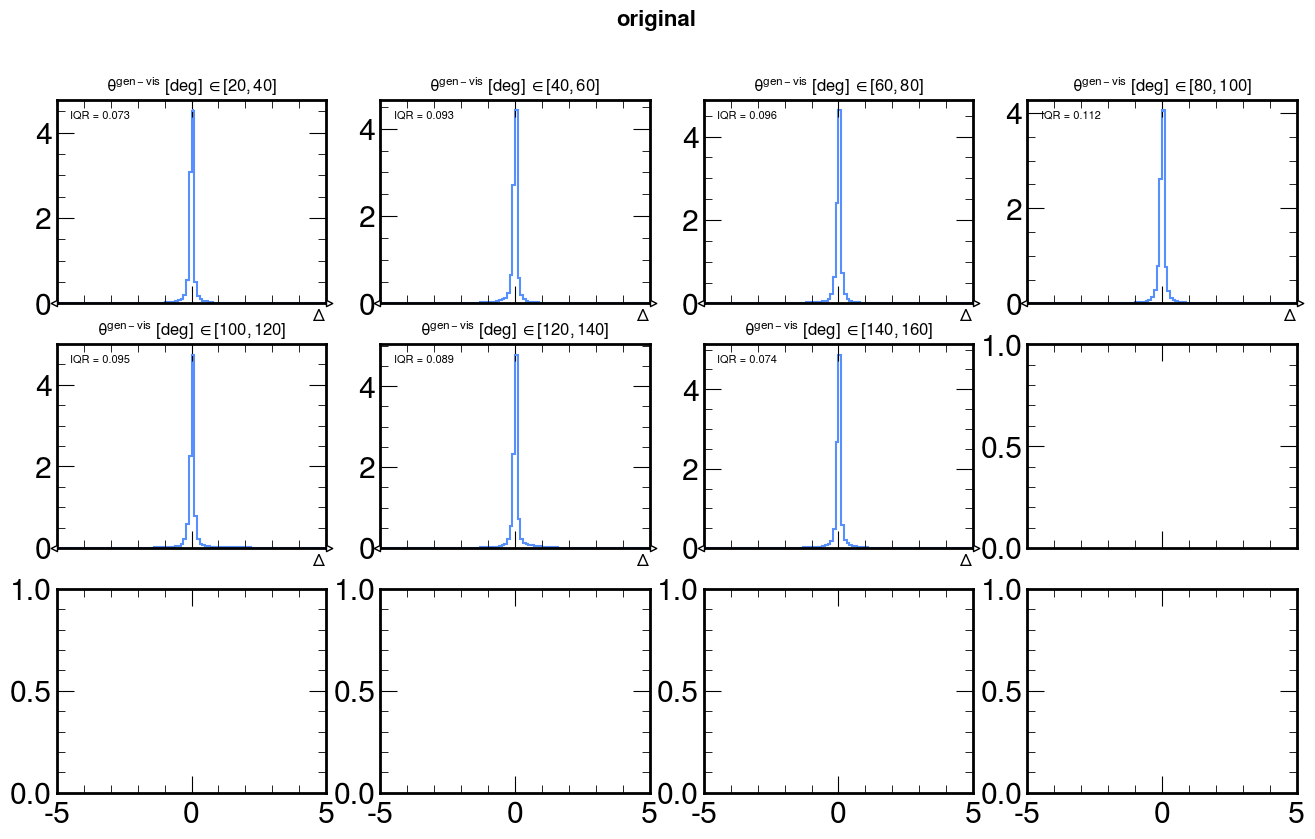

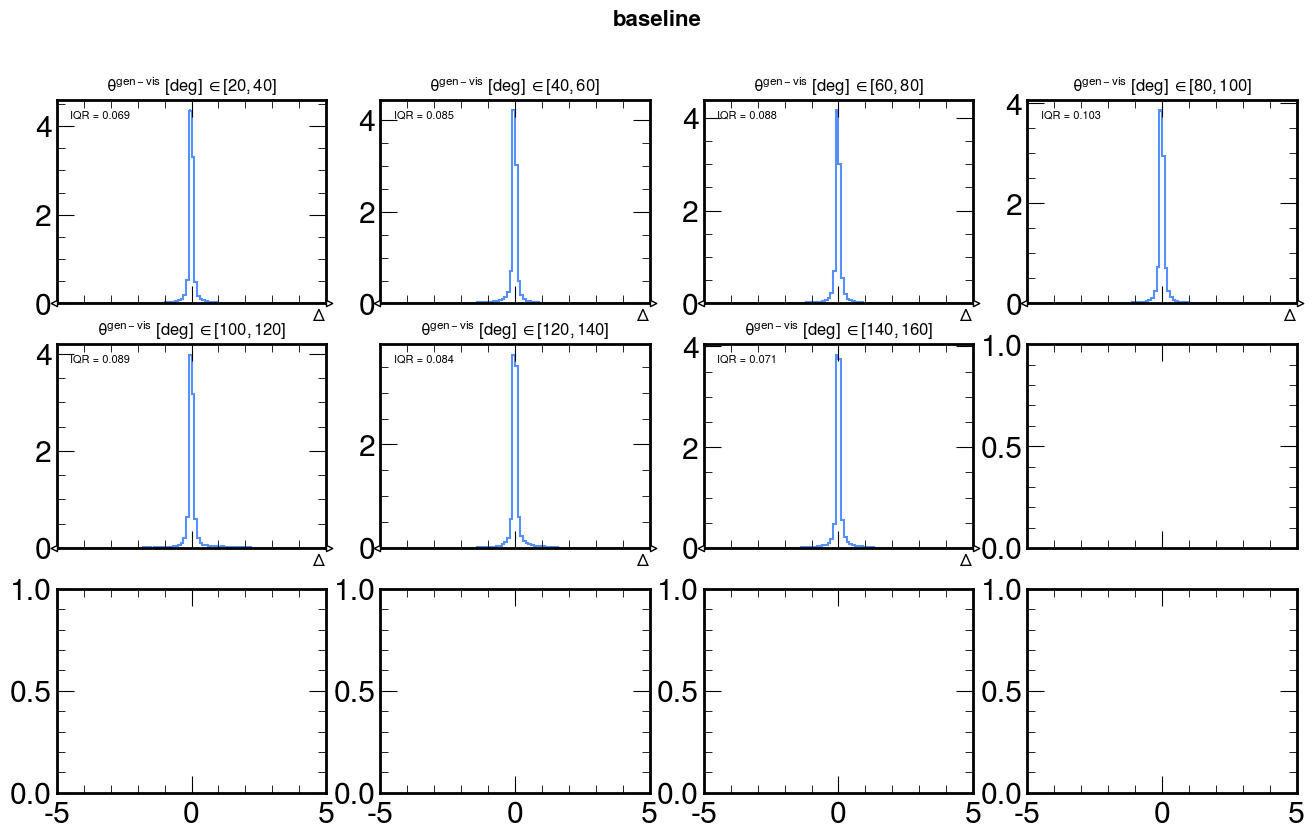

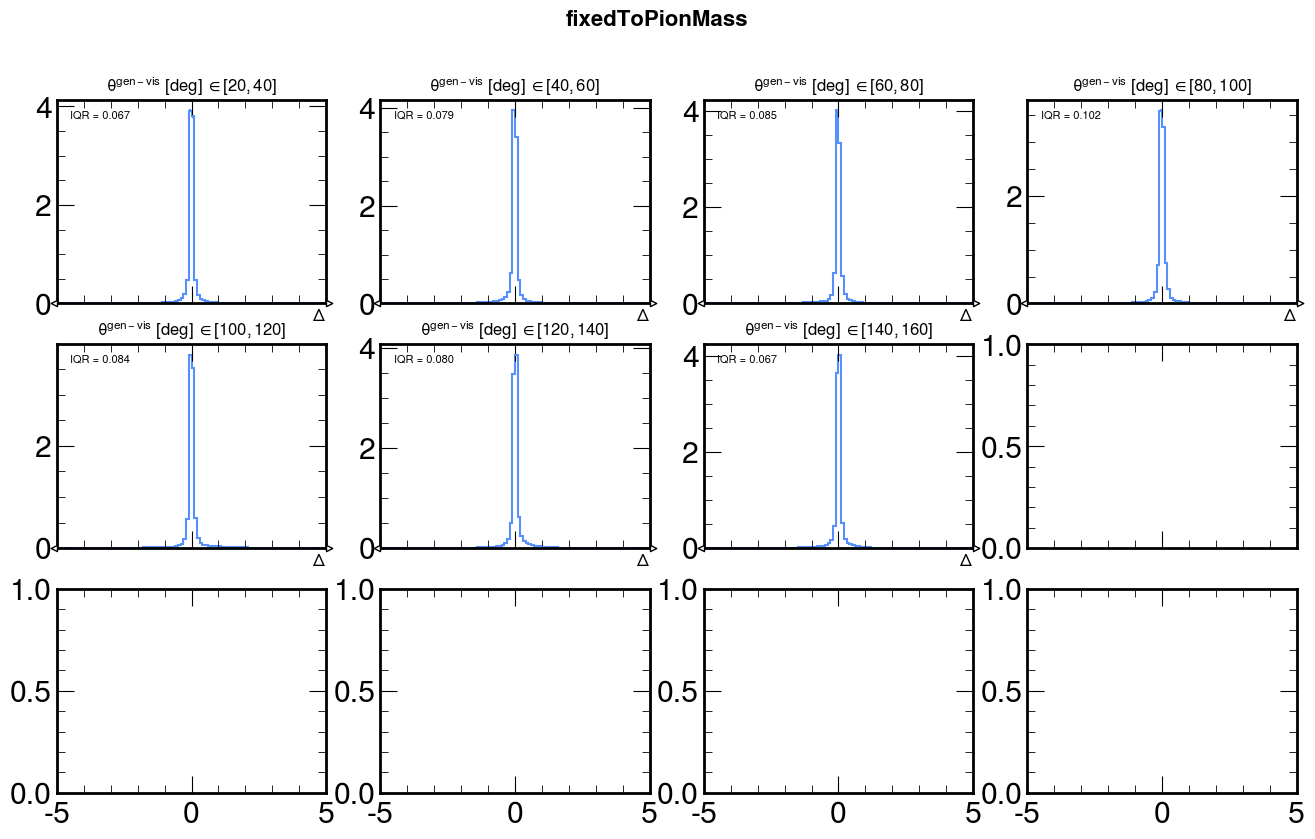

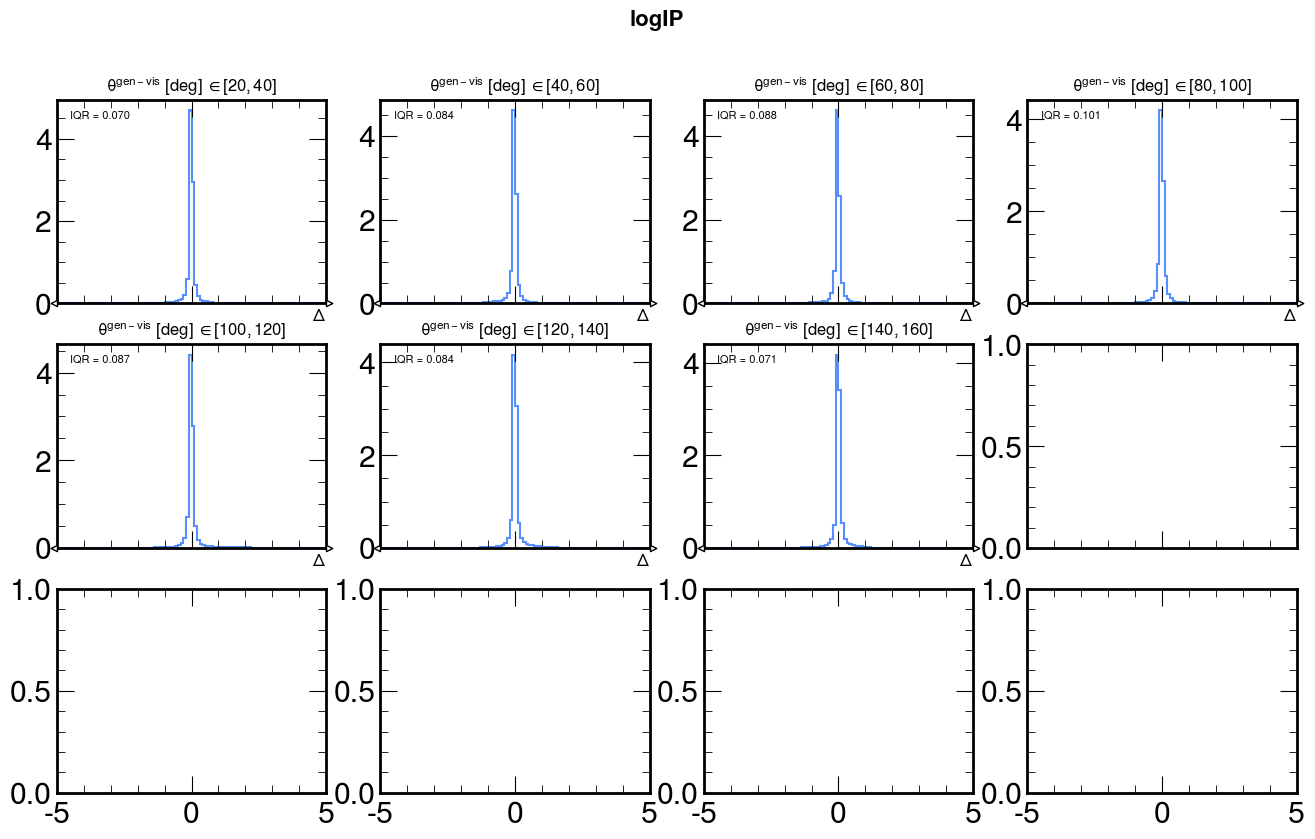

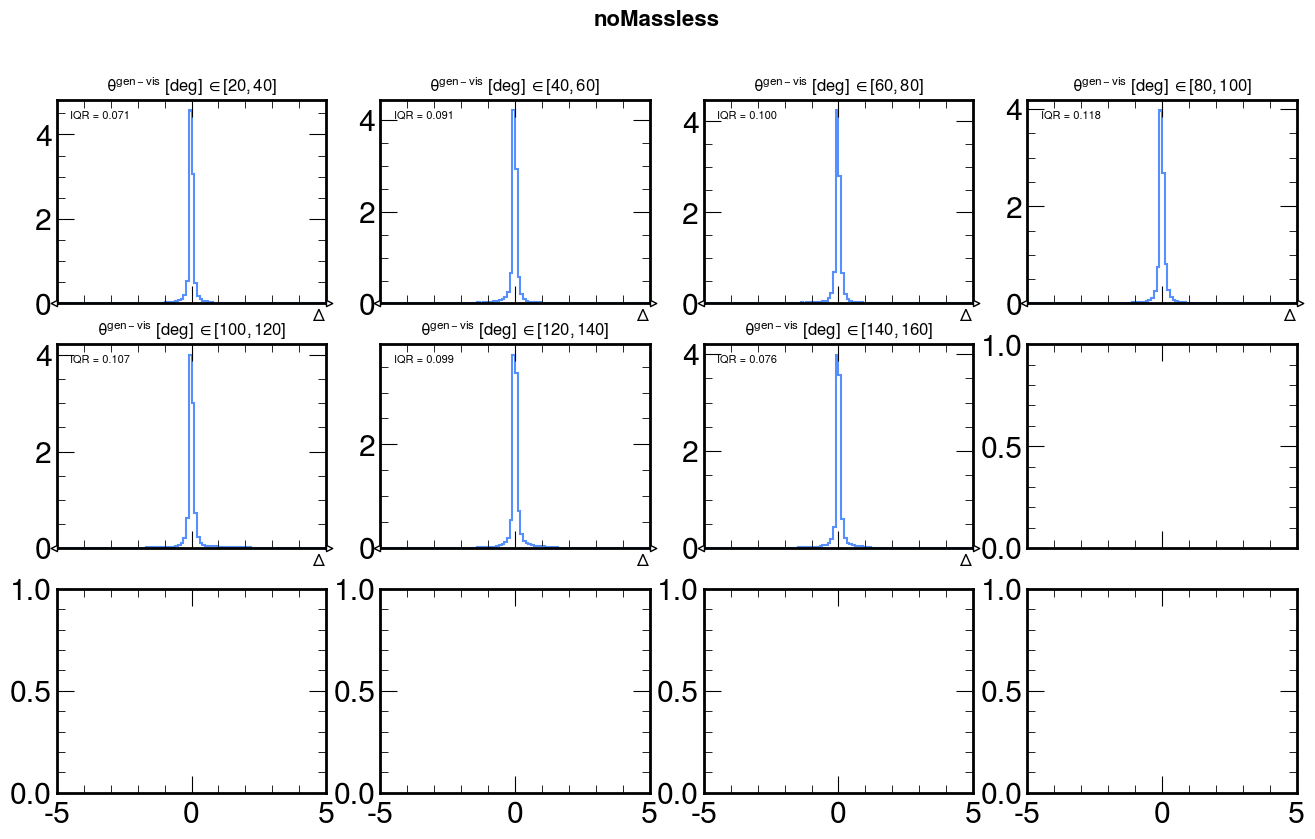

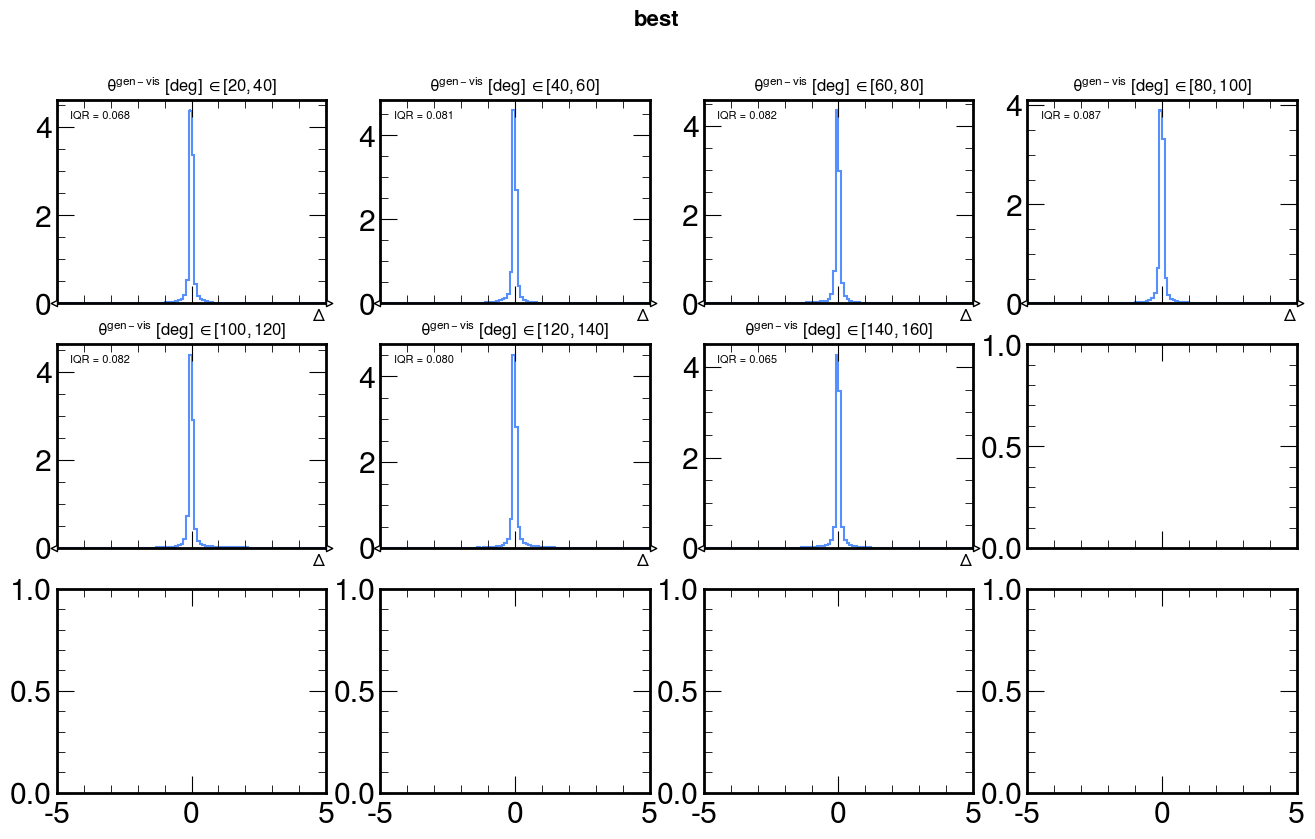

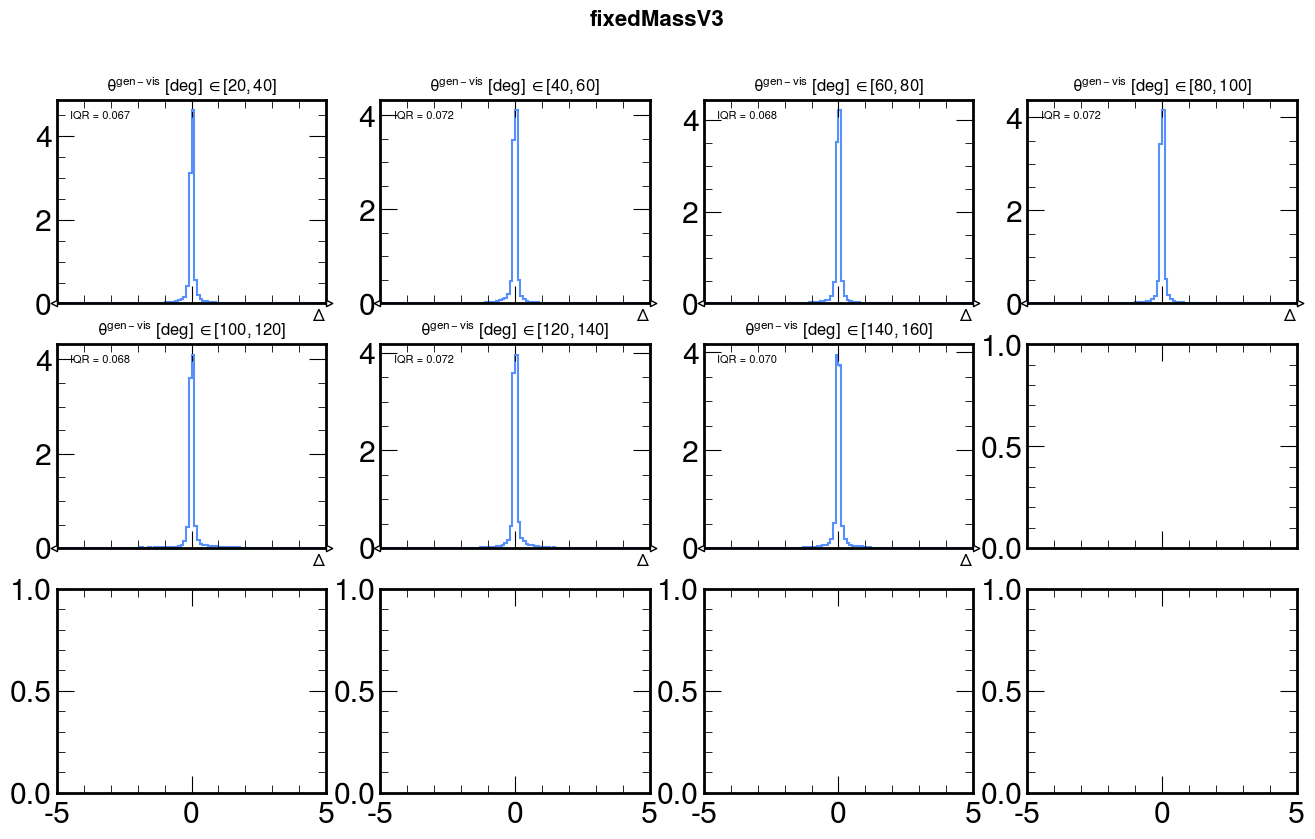

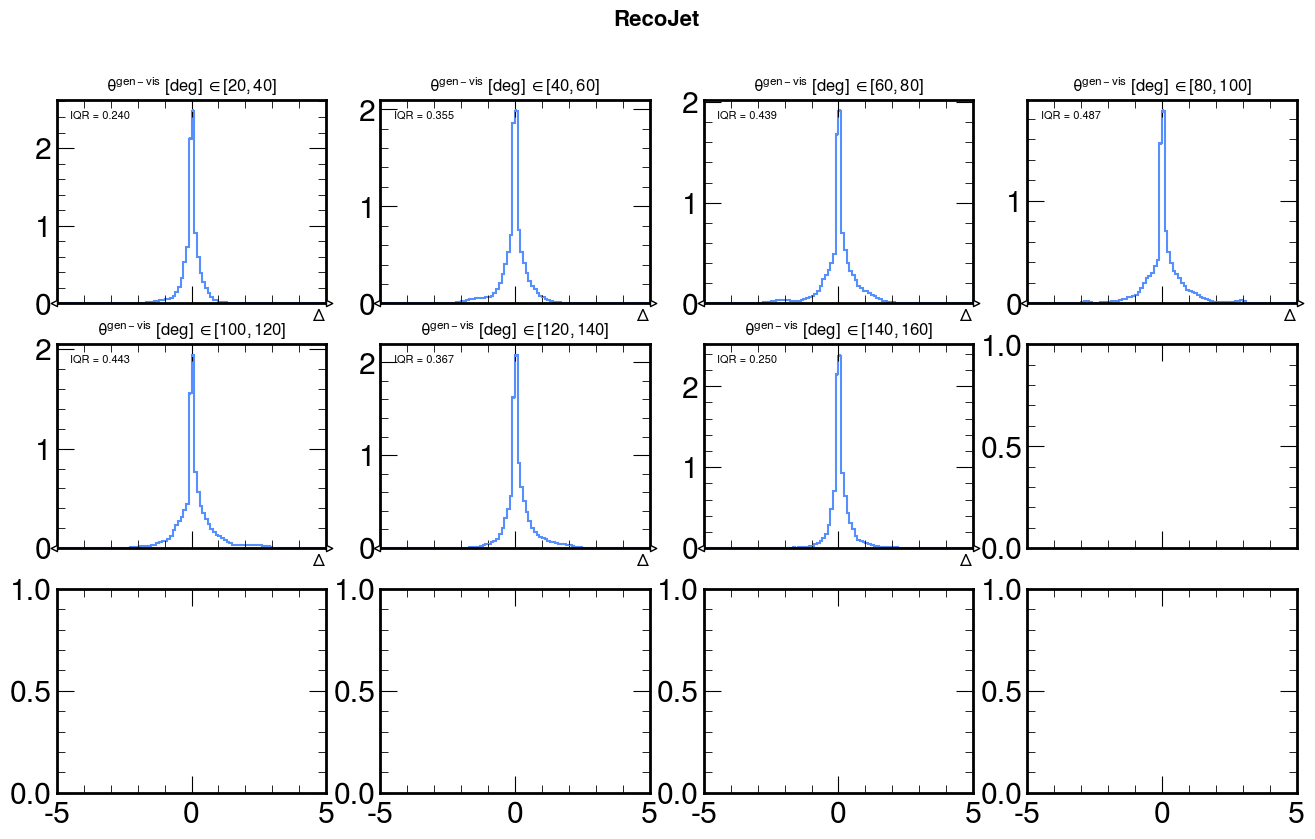

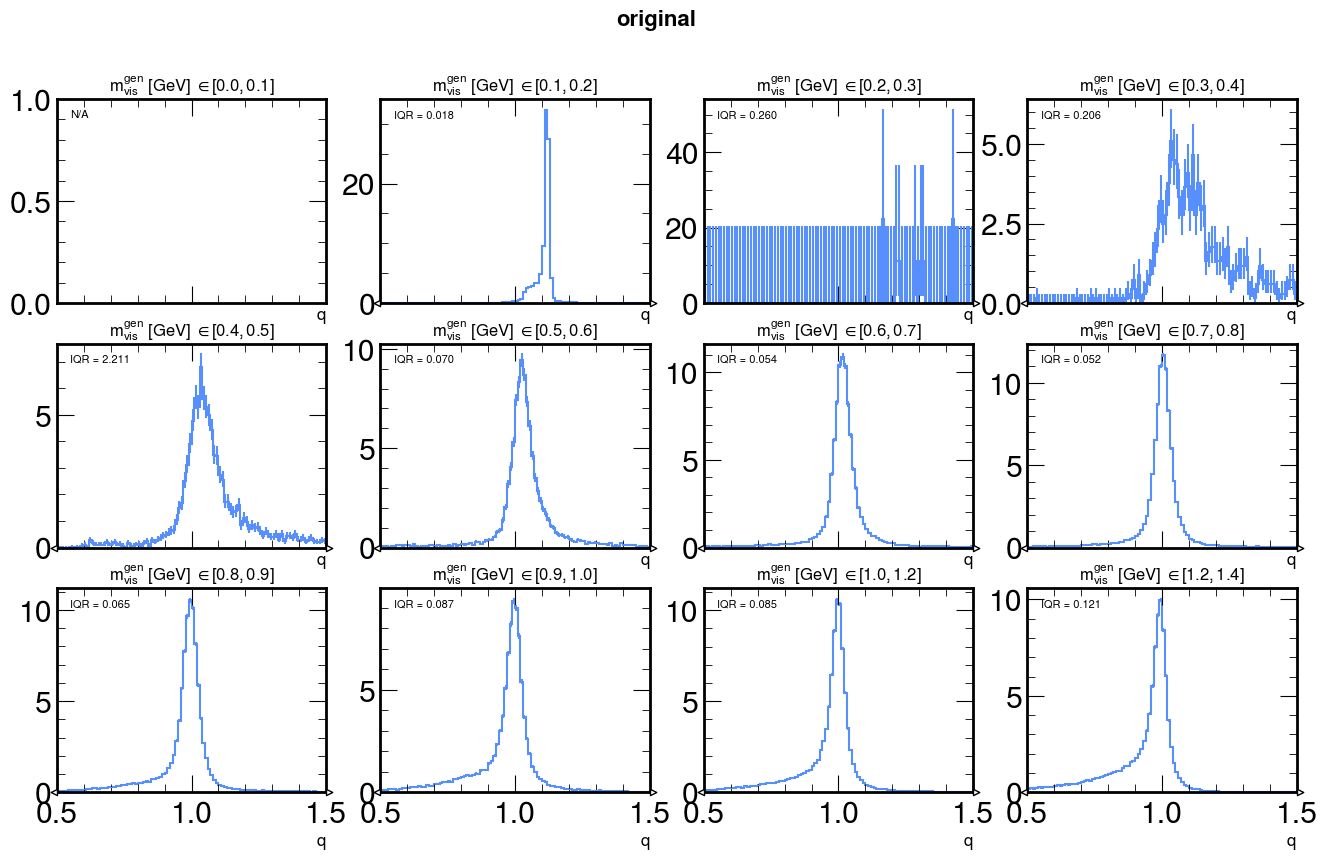

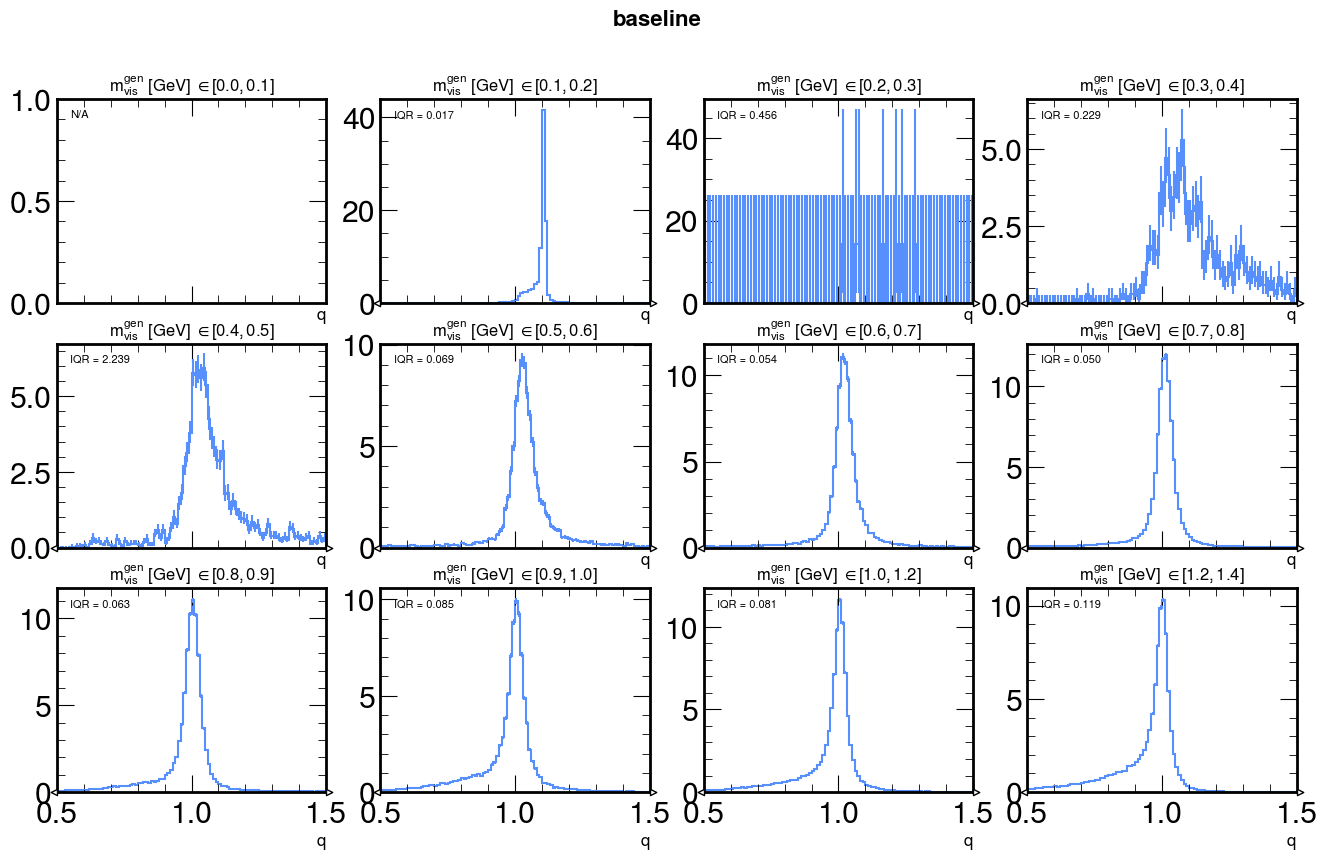

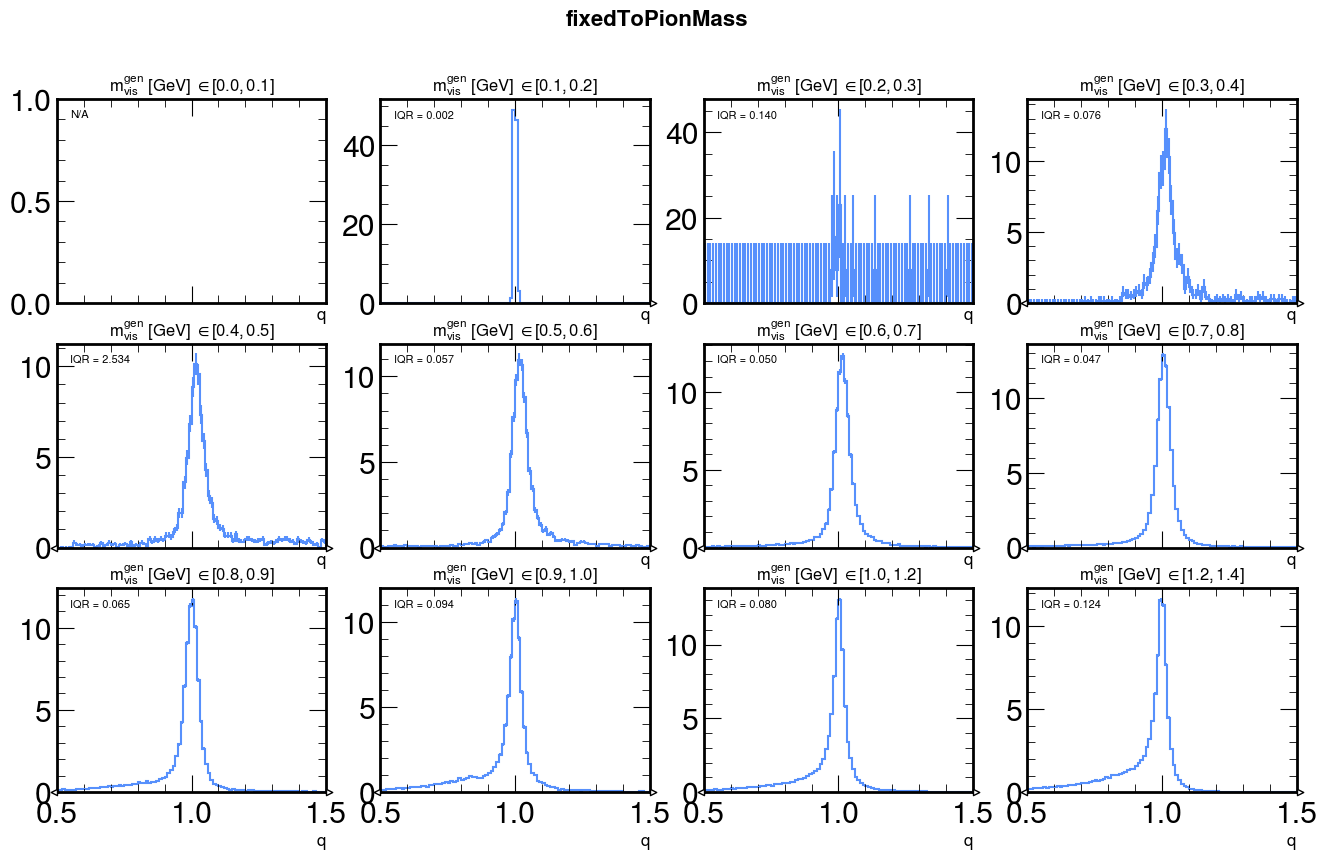

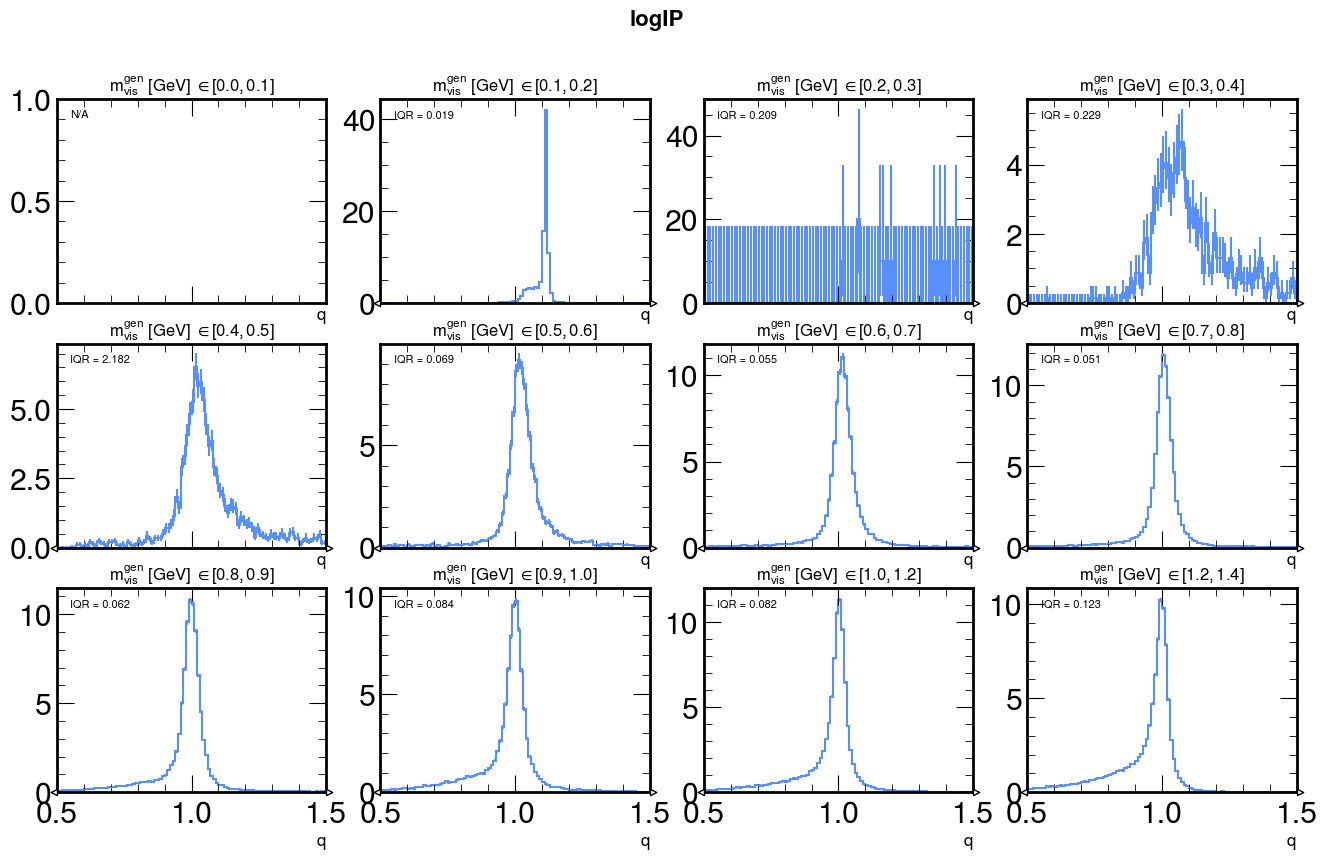

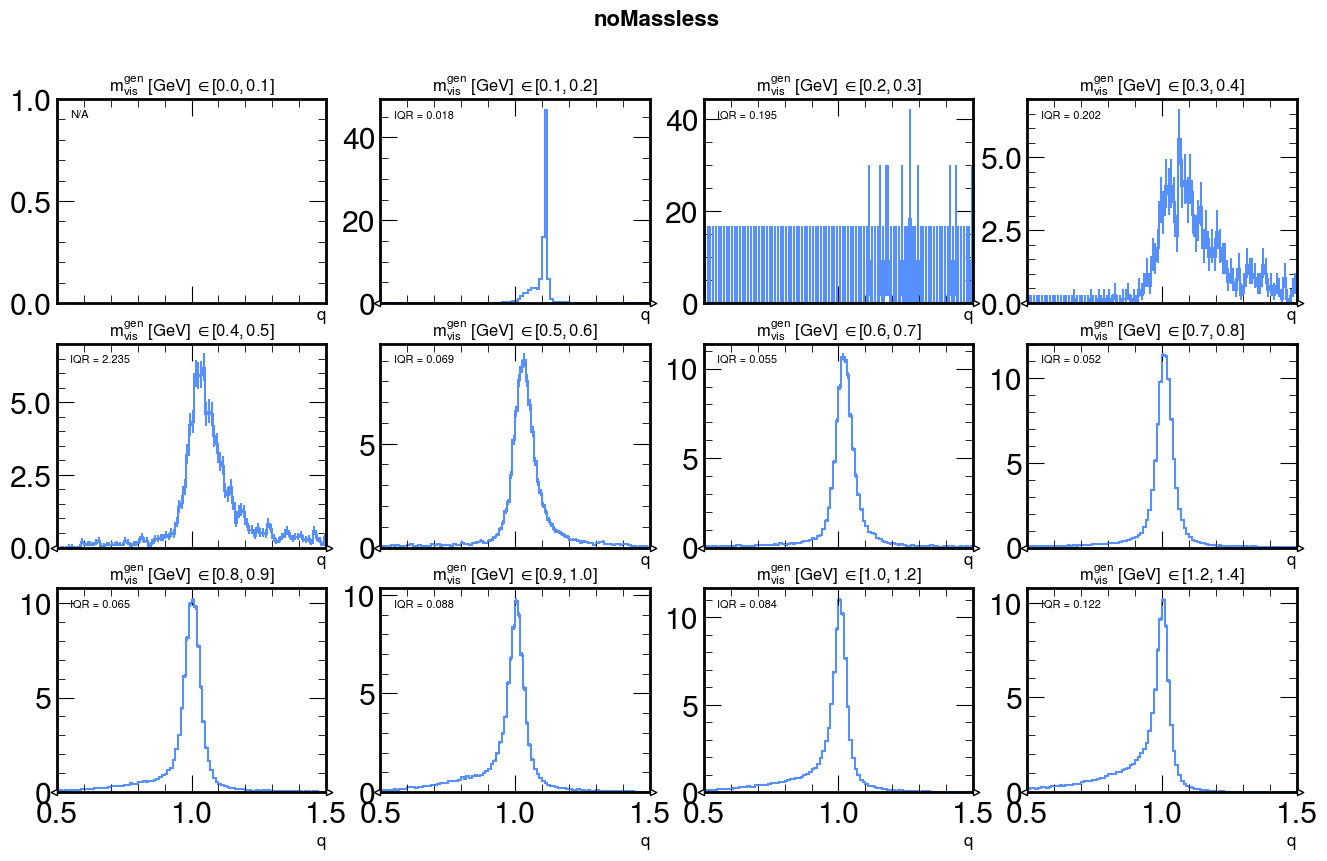

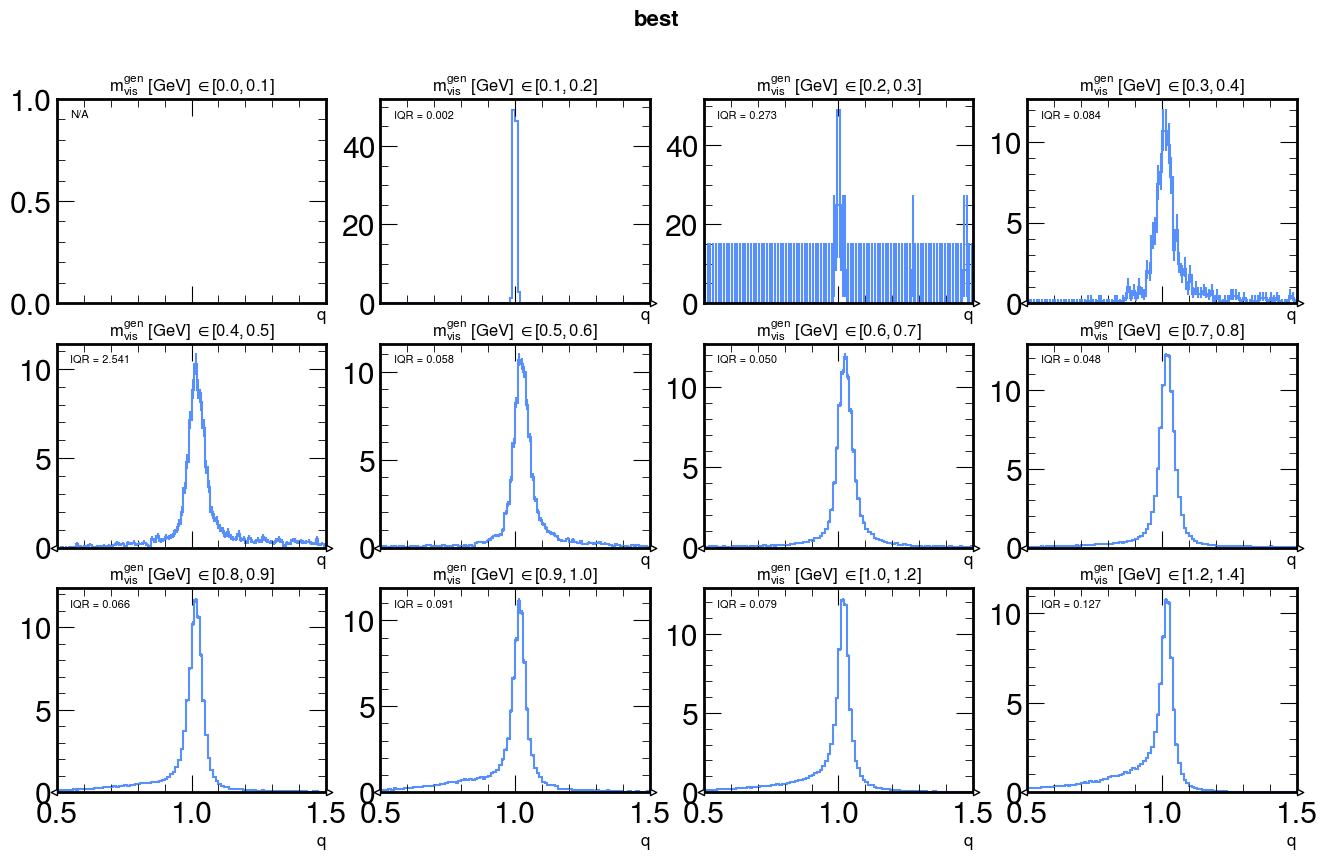

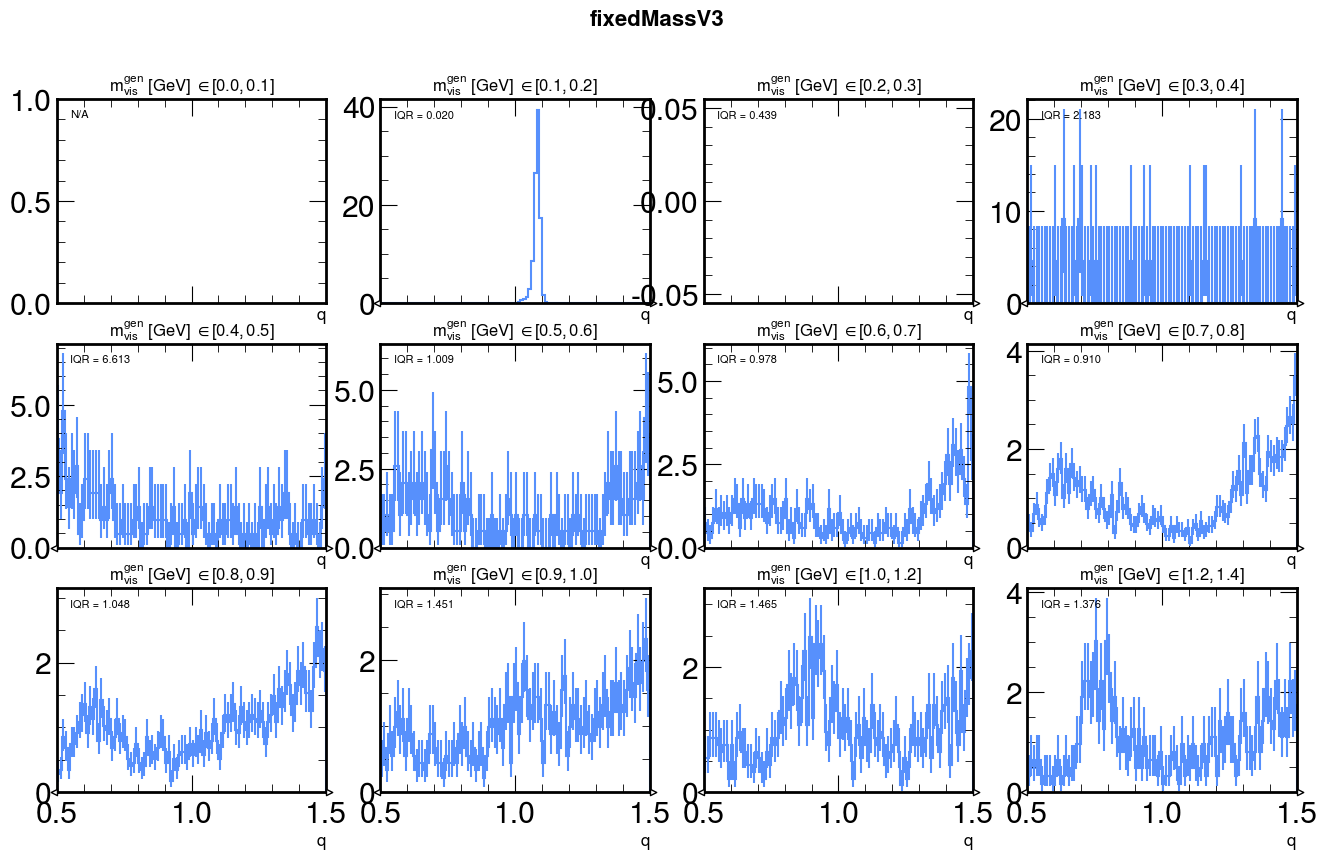

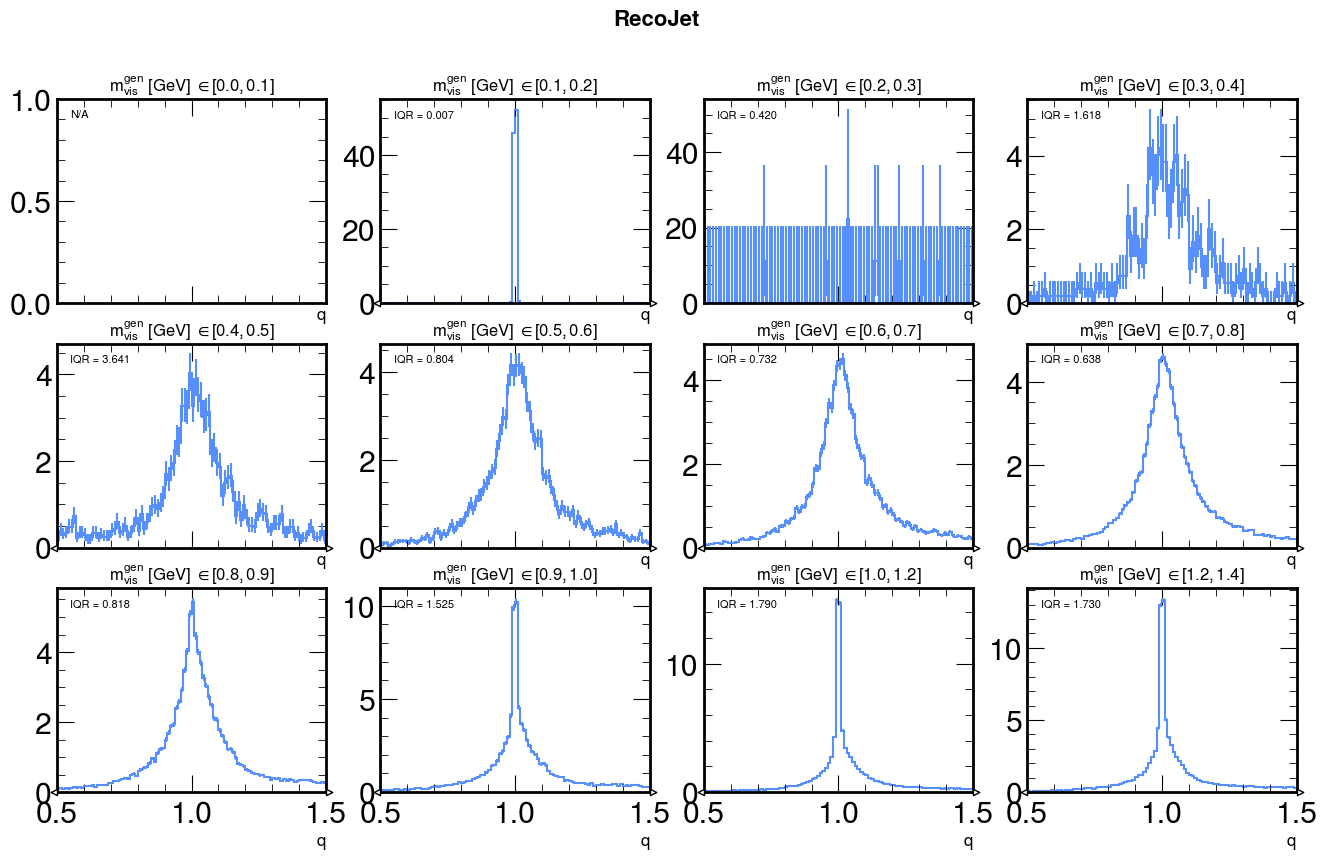

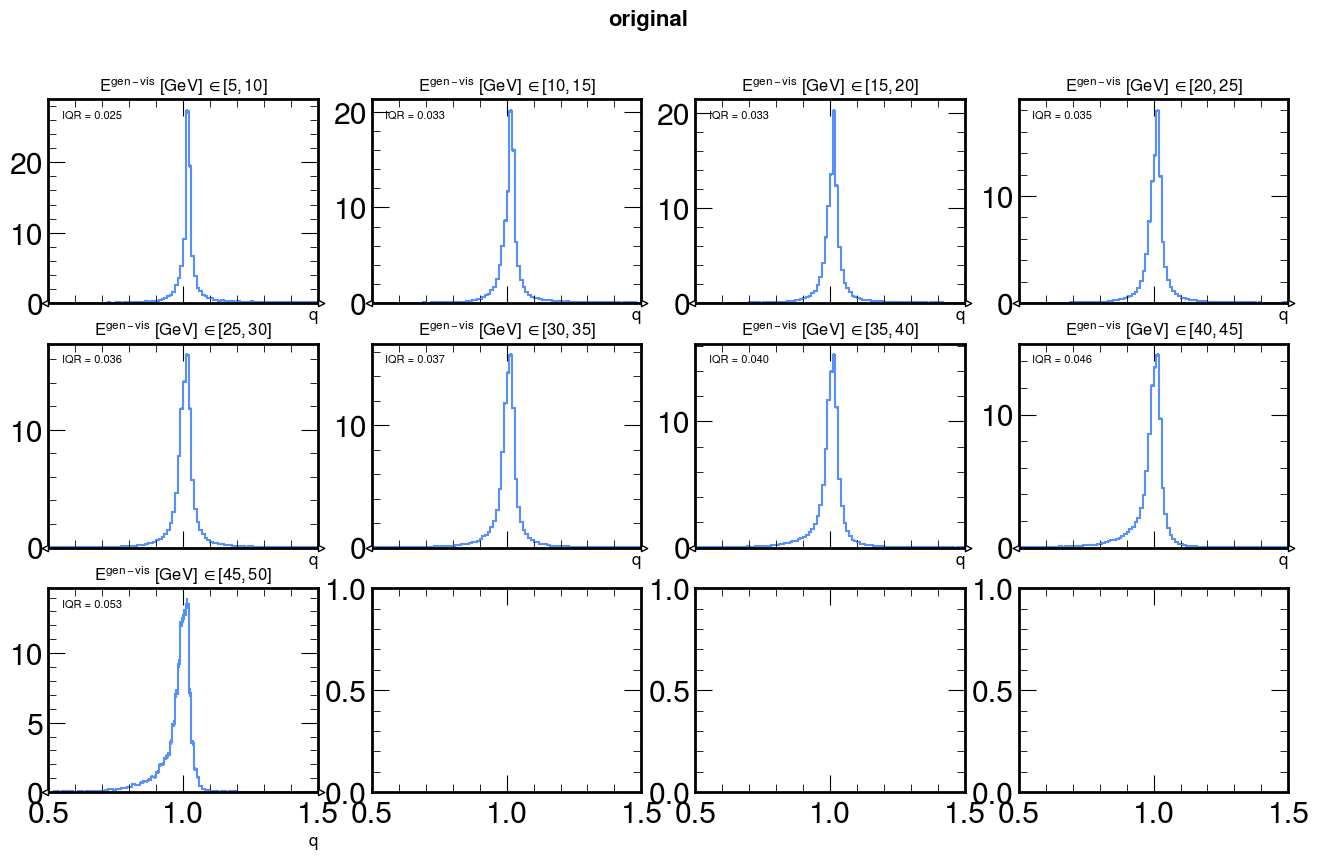

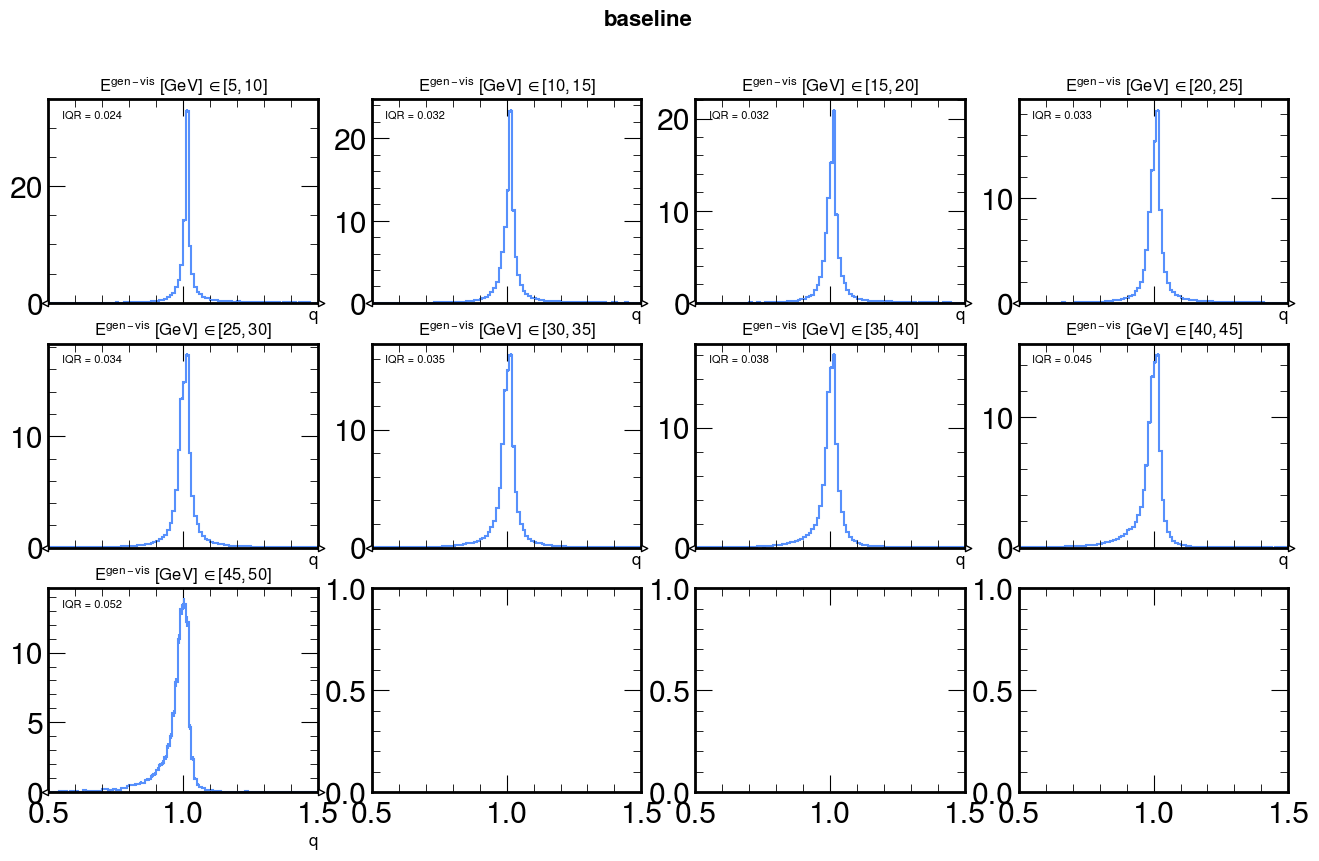

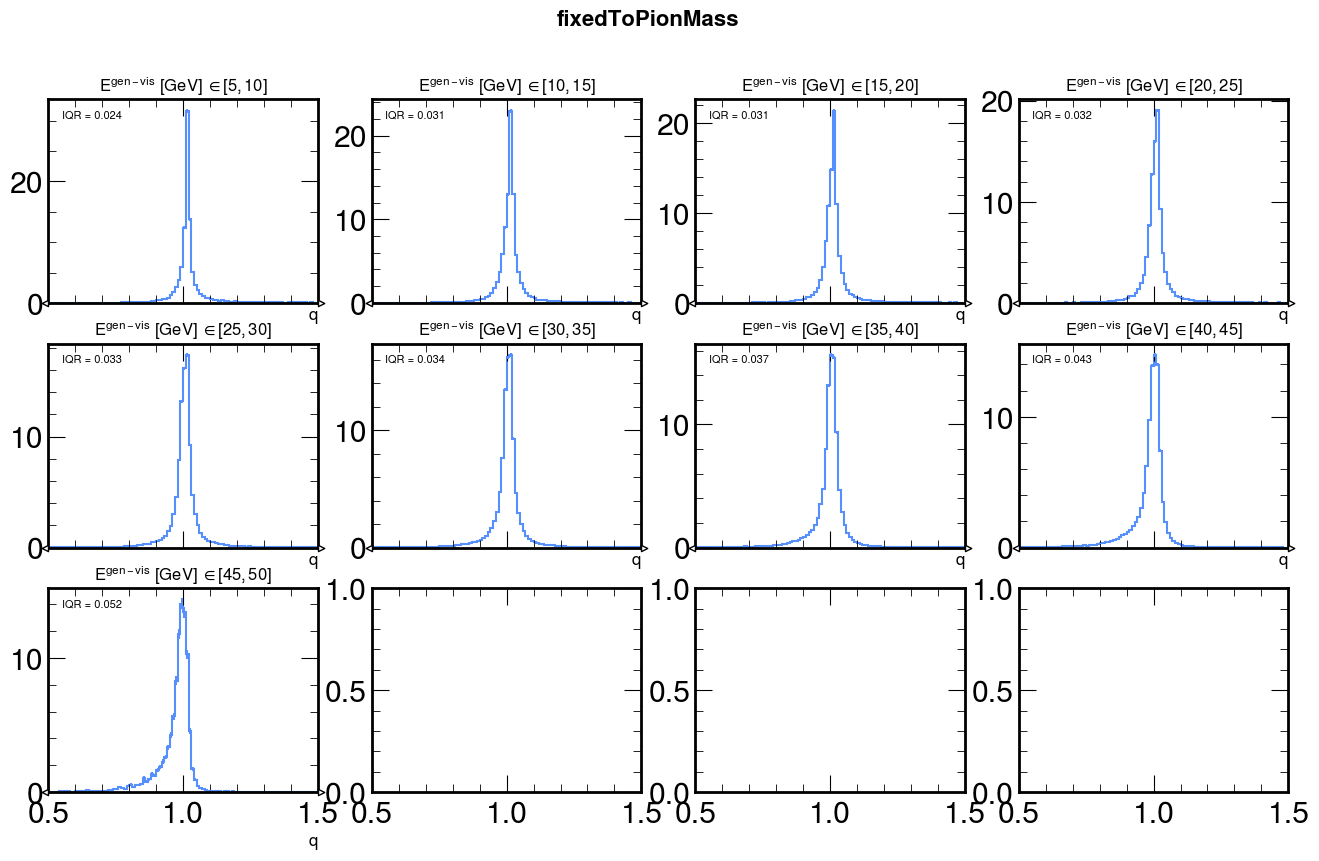

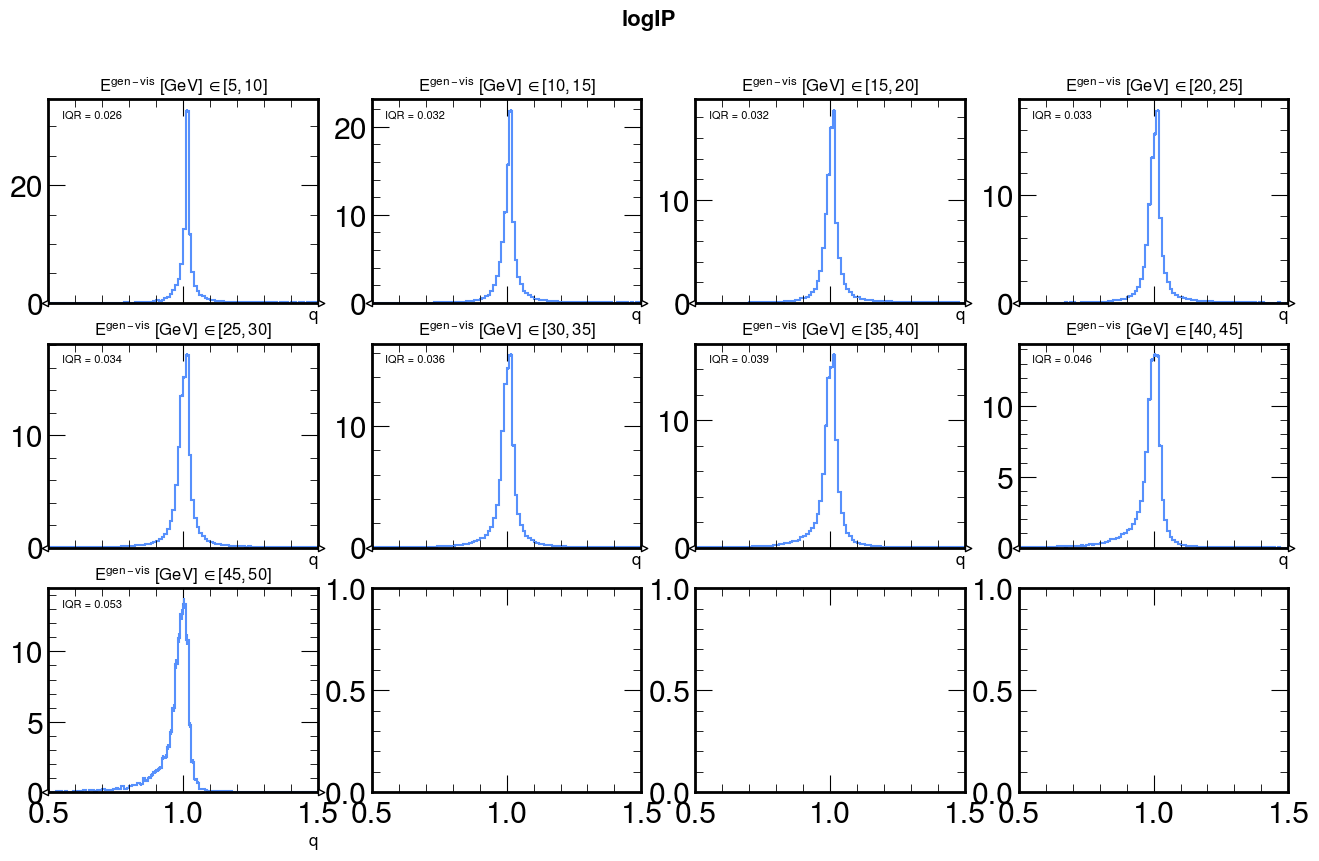

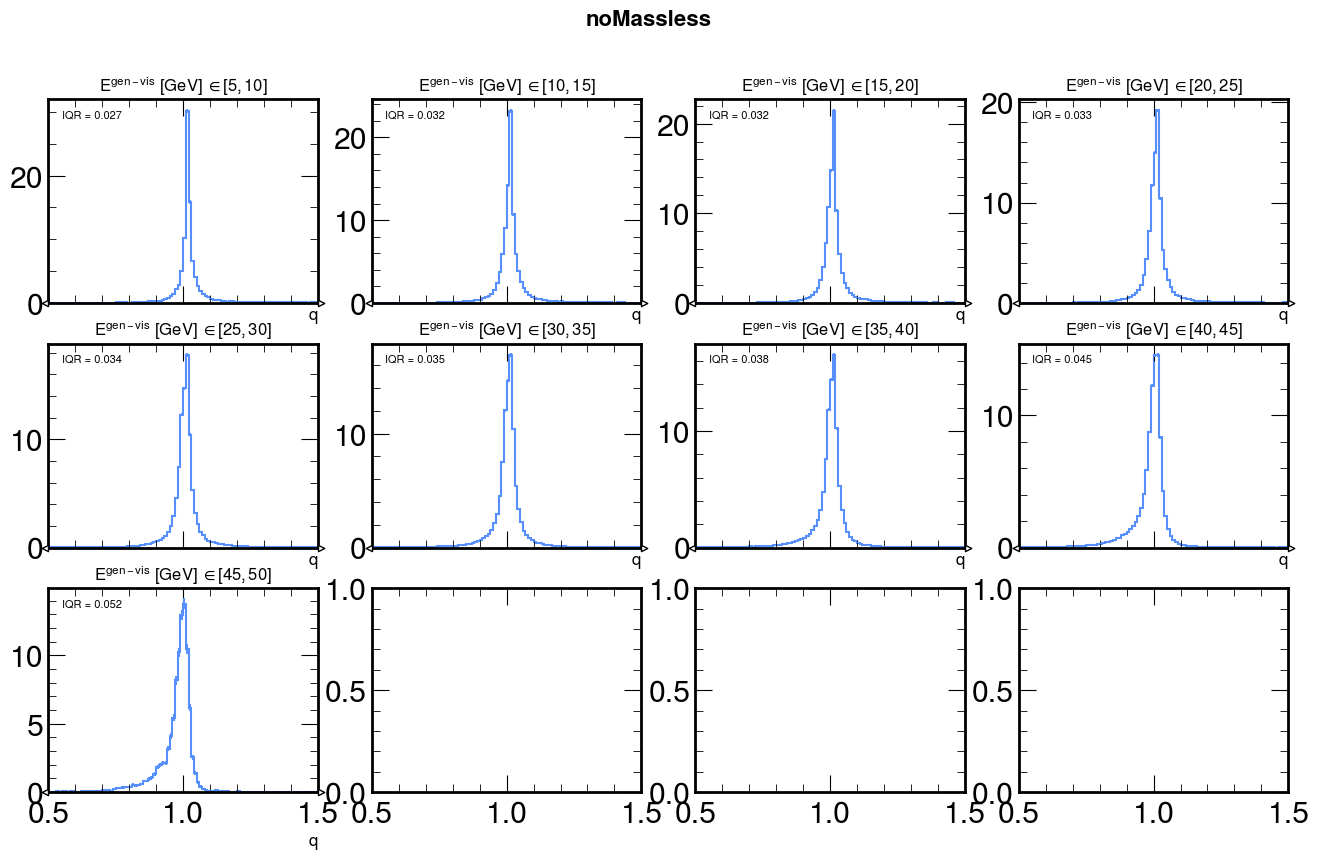

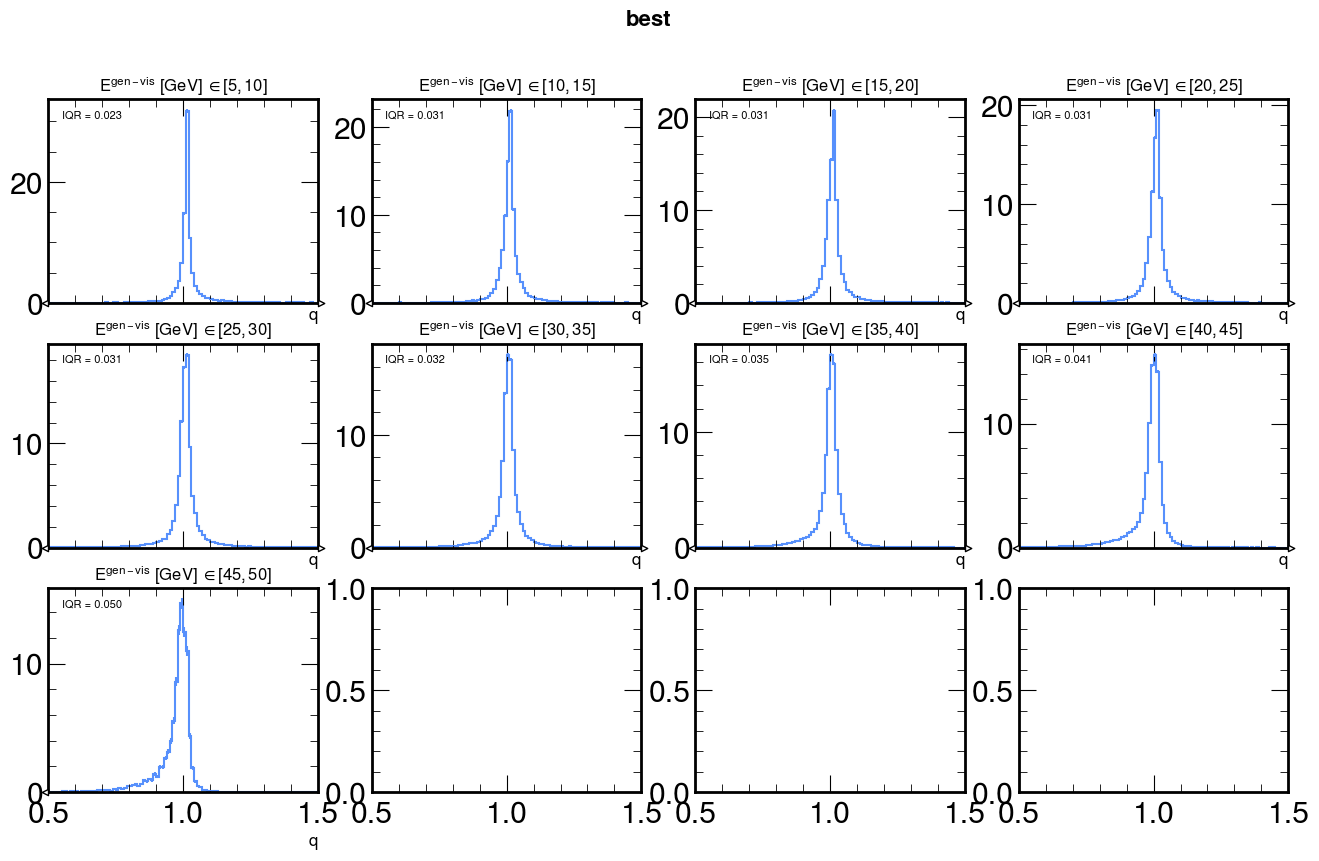

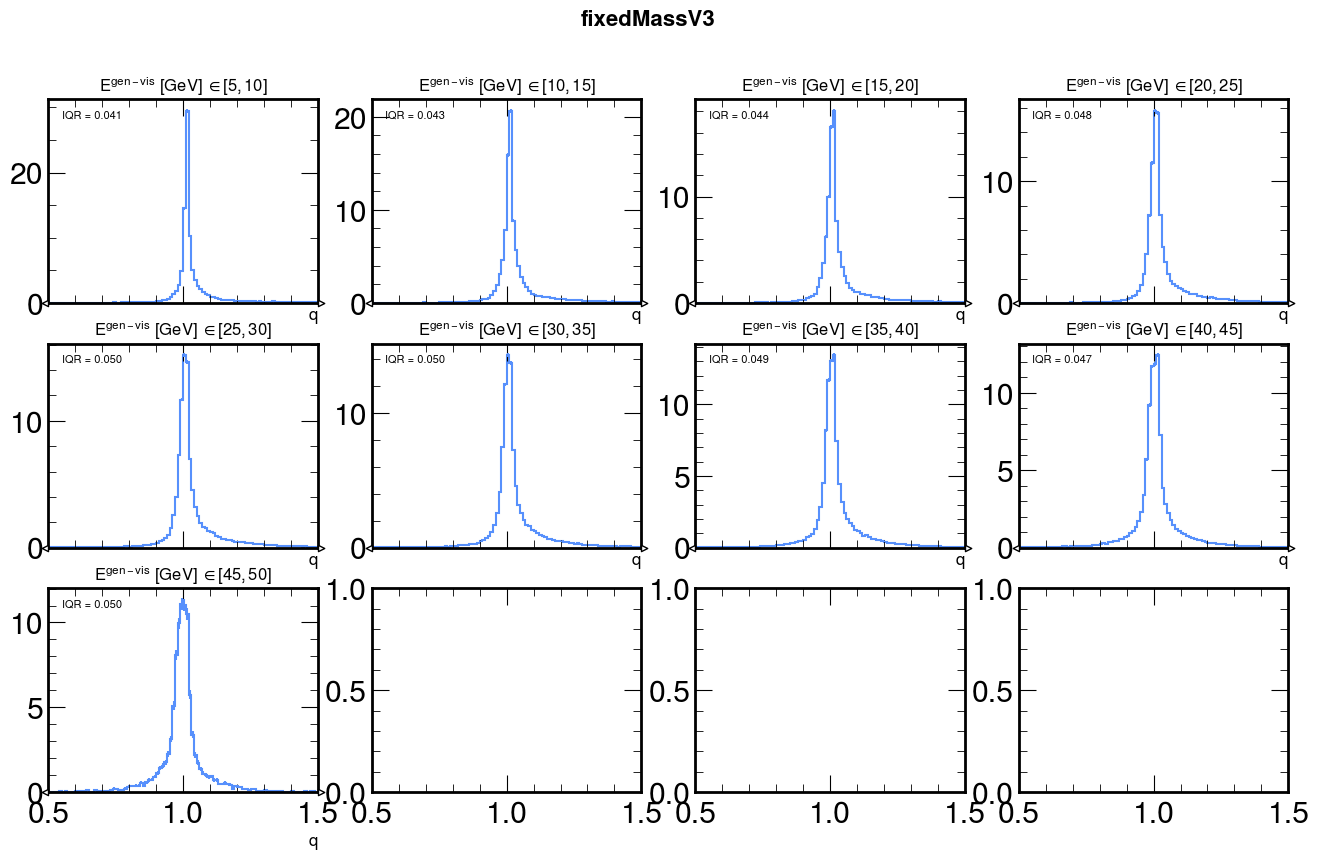

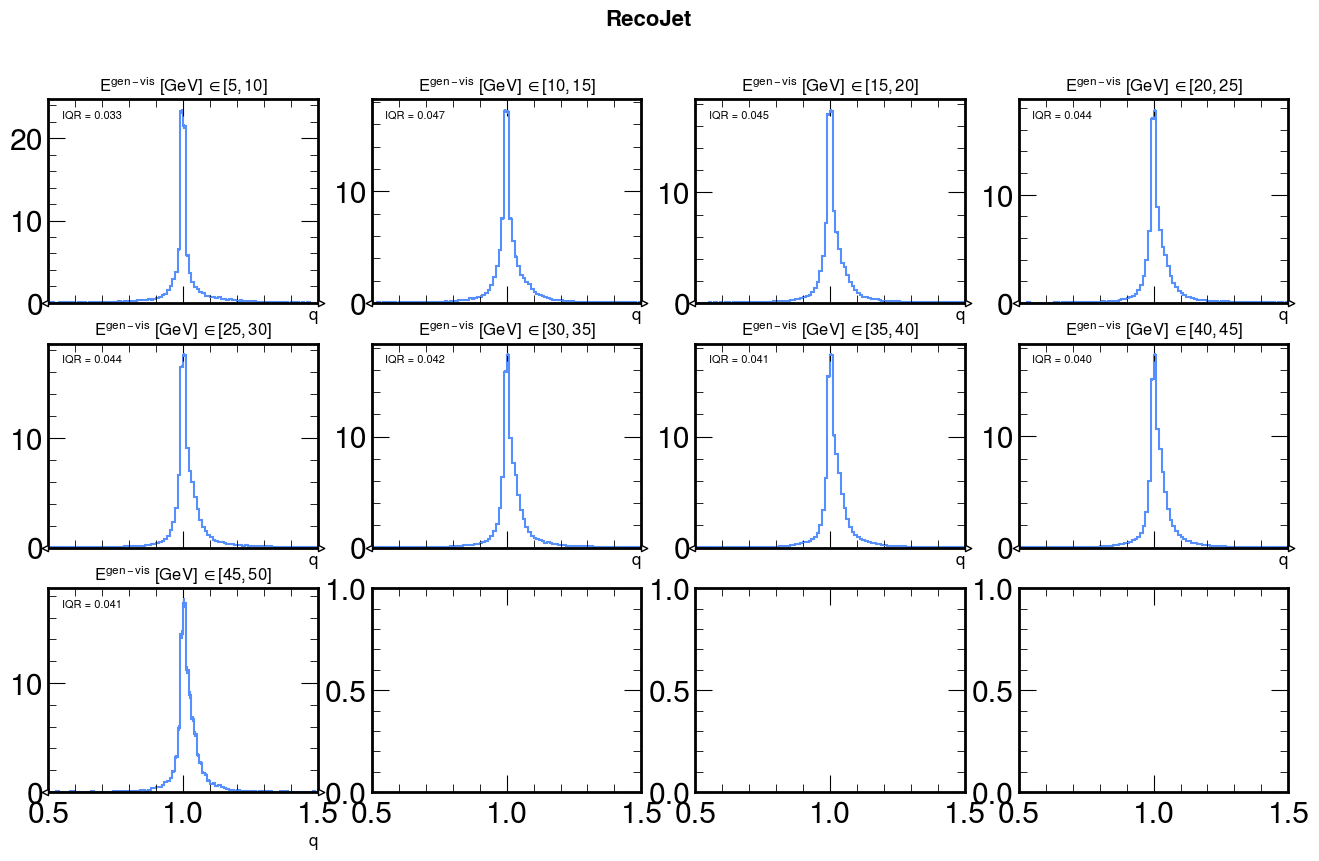

In [16]:
kme = k.KinematicsMultiEvaluator(output_dir=output_dir, cfg=cfg, sample="z")
kme.combine_results([*sts_evaluators, rj_ke], plot_pred_vs_true_2d=not skip_pred_vs_true_2d) # hps_ke

In [17]:
kme.save()